In [1]:
MODEL      = "yolov8n.pt"
EPOCHS     = 50
IMG_SIZE   = 640
BATCH      = 16
SEED       = 0

TREINAR          = True
PESOS_EXISTENTES = ""

RF_WORKSPACE = "pcb-defects-wcaof"
RF_PROJECT   = "cartas-poker-vks90"
RF_VERSION   = 4

USAR_DRIVE = True

In [2]:
!nvidia-smi
!pip install -q ultralytics roboflow

import ultralytics
ultralytics.checks()

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/235.7 GB disk)


In [4]:
import os, re, json, glob, shutil
from pathlib import Path
from collections import Counter, defaultdict

import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as IPImage
from ultralytics import YOLO

if USAR_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ = Path("/content/drive/MyDrive/TCC_YOLO")
else:
    RAIZ = Path("/content/TCC_YOLO")

NOME_RUN = f"{Path(MODEL).stem}_{EPOCHS}ep"
SAIDA    = RAIZ / NOME_RUN
FIGURAS  = SAIDA / "figuras"
TABELAS  = SAIDA / "tabelas"
for d in (FIGURAS, TABELAS):
    d.mkdir(parents=True, exist_ok=True)
print("Resultados serão salvos em:", SAIDA)

SPLITS = ["train", "val", "test"]
NOME   = {"train": "Treino", "val": "Validação", "test": "Teste"}
COR    = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}
MARCA  = {"train": "o", "val": "s", "test": "D"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e3e2de", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
})
def salvar(fig, nome):
    caminho = FIGURAS / nome
    fig.savefig(caminho)
    print("Figura salva:", caminho)

Mounted at /content/drive
Resultados serão salvos em: /content/drive/MyDrive/TCC_YOLO/yolov8n_50ep


In [6]:
try:
    from google.colab import userdata
    API_KEY = userdata.get("ROBOFLOW_API_KEY")
except Exception:
    import getpass
    API_KEY = getpass.getpass("Chave da API do Roboflow: ")

from roboflow import Roboflow
os.makedirs("/content/datasets", exist_ok=True)
os.chdir("/content/datasets")
rf = Roboflow(api_key=API_KEY)
dataset = rf.workspace(RF_WORKSPACE).project(RF_PROJECT).version(RF_VERSION).download("yolov8")
DS = Path(dataset.location)
print("Dataset em:", DS)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Cartas-Poker-4 in yolov8:: 100%|██████████| 13487/13487 [00:01<00:00, 6969.00it/s]


Dataset em: /content/datasets/Cartas-Poker-4


In [7]:
with open(DS / "data.yaml") as f:
    cfg = yaml.safe_load(f)

PASTA = {"train": "train", "val": "valid", "test": "test"}
for s in SPLITS:
    assert (DS / PASTA[s] / "images").is_dir(), f"Conjunto '{s}' não encontrado em {DS / PASTA[s]}"

cfg.update({"path": str(DS), "train": "train/images", "val": "valid/images", "test": "test/images"})
DATA_YAML = DS / "data_tcc.yaml"
with open(DATA_YAML, "w") as f:
    yaml.safe_dump(cfg, f, allow_unicode=True, sort_keys=False)

NOMES = cfg["names"] if isinstance(cfg["names"], list) else [cfg["names"][i] for i in sorted(cfg["names"])]
print(f"{len(NOMES)} classes | data.yaml: {DATA_YAML}")

52 classes | data.yaml: /content/datasets/Cartas-Poker-4/data_tcc.yaml


In [8]:
EXT_IMG = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def nome_original(arquivo):
    stem = Path(arquivo).stem
    return stem.split(".rf.")[0] if ".rf." in stem else stem

def analisar_conjunto(split):
    pasta = DS / PASTA[split]
    imagens = sorted(p for p in (pasta / "images").iterdir() if p.suffix.lower() in EXT_IMG)
    inst = Counter()
    origs_classe = defaultdict(set)
    sem_rotulo = 0
    for img in imagens:
        lbl = pasta / "labels" / (img.stem + ".txt")
        linhas = [l.split() for l in lbl.read_text().splitlines() if l.strip()] if lbl.exists() else []
        if not linhas:
            sem_rotulo += 1
        for l in linhas:
            c = int(float(l[0]))
            inst[c] += 1
            origs_classe[c].add(nome_original(img.name))
    originais = {nome_original(i.name) for i in imagens}
    return {"imagens": len(imagens), "instancias": sum(inst.values()), "sem_rotulo": sem_rotulo,
            "originais": originais, "inst_classe": inst, "orig_classe": origs_classe}

info = {s: analisar_conjunto(s) for s in SPLITS}

tot_img  = sum(info[s]["imagens"] for s in SPLITS)
tot_inst = sum(info[s]["instancias"] for s in SPLITS)
tot_orig = sum(len(info[s]["originais"]) for s in SPLITS)

composicao = pd.DataFrame([{
    "Conjunto": NOME[s],
    "Imagens": info[s]["imagens"],
    "% imagens": 100 * info[s]["imagens"] / tot_img,
    "Instâncias": info[s]["instancias"],
    "% instâncias": 100 * info[s]["instancias"] / tot_inst,
    "Imagens originais": len(info[s]["originais"]),
    "% originais": 100 * len(info[s]["originais"]) / tot_orig,
    "Fator de aumento": info[s]["imagens"] / max(1, len(info[s]["originais"])),
    "Sem rótulo": info[s]["sem_rotulo"],
} for s in SPLITS])
composicao.loc[len(composicao)] = ["Total", tot_img, 100.0, tot_inst, 100.0, tot_orig, 100.0,
                                   tot_img / max(1, tot_orig), sum(info[s]["sem_rotulo"] for s in SPLITS)]
composicao.to_csv(TABELAS / "composicao_dataset.csv", index=False, sep=";", decimal=",")
display(composicao.style.format({"% imagens": "{:.1f}%", "% instâncias": "{:.1f}%",
                                 "% originais": "{:.1f}%", "Fator de aumento": "{:.2f}×"}).hide(axis="index"))

print("\nVerificação de vazamento entre conjuntos:")
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    comum = info[a]["originais"] & info[b]["originais"]
    alerta = "  <-- ATENÇÃO: a mesma foto aparece nos dois conjuntos" if comum else ""
    print(f"  {NOME[a]} ∩ {NOME[b]}: {len(comum)} fotos originais em comum{alerta}")
    if comum:
        print("    exemplos:", sorted(comum)[:5])
print("  (o nome original vem do arquivo enviado ao Roboflow; nomes repetidos de fotos diferentes também apareceriam aqui)")

Conjunto,Imagens,% imagens,Instâncias,% instâncias,Imagens originais,% originais,Fator de aumento,Sem rótulo
Treino,6285,93.2%,19182,92.6%,2095,82.1%,3.00×,3
Validação,283,4.2%,930,4.5%,283,11.1%,1.00×,0
Teste,173,2.6%,602,2.9%,173,6.8%,1.00×,0
Total,6741,100.0%,20714,100.0%,2551,100.0%,2.64×,3



Verificação de vazamento entre conjuntos:
  Treino ∩ Validação: 0 fotos originais em comum
  Treino ∩ Teste: 0 fotos originais em comum
  Validação ∩ Teste: 0 fotos originais em comum
  (o nome original vem do arquivo enviado ao Roboflow; nomes repetidos de fotos diferentes também apareceriam aqui)


In [9]:
por_classe = pd.DataFrame({"Classe": NOMES})
for s in SPLITS:
    por_classe[f"Instâncias ({NOME[s]})"] = [info[s]["inst_classe"].get(i, 0) for i in range(len(NOMES))]
    por_classe[f"Originais ({NOME[s]})"]  = [len(info[s]["orig_classe"].get(i, ())) for i in range(len(NOMES))]
por_classe["Instâncias (total)"] = por_classe[[f"Instâncias ({NOME[s]})" for s in SPLITS]].sum(axis=1)
por_classe["Originais (total)"]  = por_classe[[f"Originais ({NOME[s]})" for s in SPLITS]].sum(axis=1)
por_classe.to_csv(TABELAS / "instancias_por_classe.csv", index=False, sep=";", decimal=",")

r = por_classe["Instâncias (total)"]; o = por_classe["Originais (total)"]
print(f"Instâncias por classe (total): média {r.mean():.0f}, mín {r.min()} ({por_classe.Classe[r.idxmin()]}), máx {r.max()} ({por_classe.Classe[r.idxmax()]})")
print(f"Fotos originais por classe:    média {o.mean():.0f}, mín {o.min()}, máx {o.max()}")
print("→ Use esses números para responder se as ~450 imagens por classe incluem ou não o aumento de dados.")
display(por_classe.head(10))

Instâncias por classe (total): média 398, mín 378 (2 Trefoils), máx 420 (8 Diamonds)
Fotos originais por classe:    média 152, mín 150, máx 157
→ Use esses números para responder se as ~450 imagens por classe incluem ou não o aumento de dados.


,Classe,Instâncias (Treino),Originais (Treino),Instâncias (Validação),Originais (Validação),Instâncias (Teste),Originais (Teste),Instâncias (total),Originais (total)
0,10 Diamonds,354,118,20,20,12,12,386,150
1,10 Hearts,363,120,19,19,11,11,393,150
2,10 Spades,366,122,18,18,11,11,395,151
3,10 Trefoils,351,116,23,22,12,12,386,150
4,2 Diamonds,360,120,19,19,13,13,392,152
5,2 Hearts,366,122,18,18,12,12,396,152
6,2 Spades,366,121,18,18,12,12,396,151
7,2 Trefoils,342,114,23,23,13,13,378,150
8,3 Diamonds,357,119,22,22,11,11,390,152
9,3 Hearts,354,118,19,19,13,13,386,150


Figura salva: /content/drive/MyDrive/TCC_YOLO/yolov8n_50ep/figuras/01_divisao_dataset.png


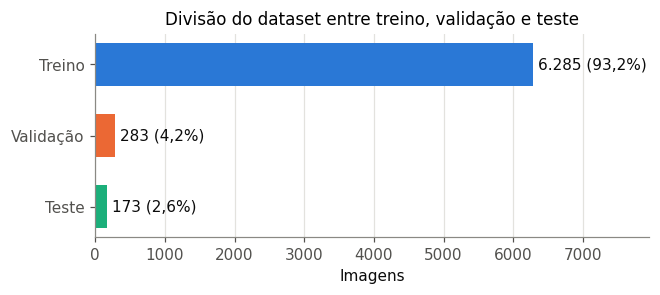

Figura salva: /content/drive/MyDrive/TCC_YOLO/yolov8n_50ep/figuras/02_instancias_por_classe.png


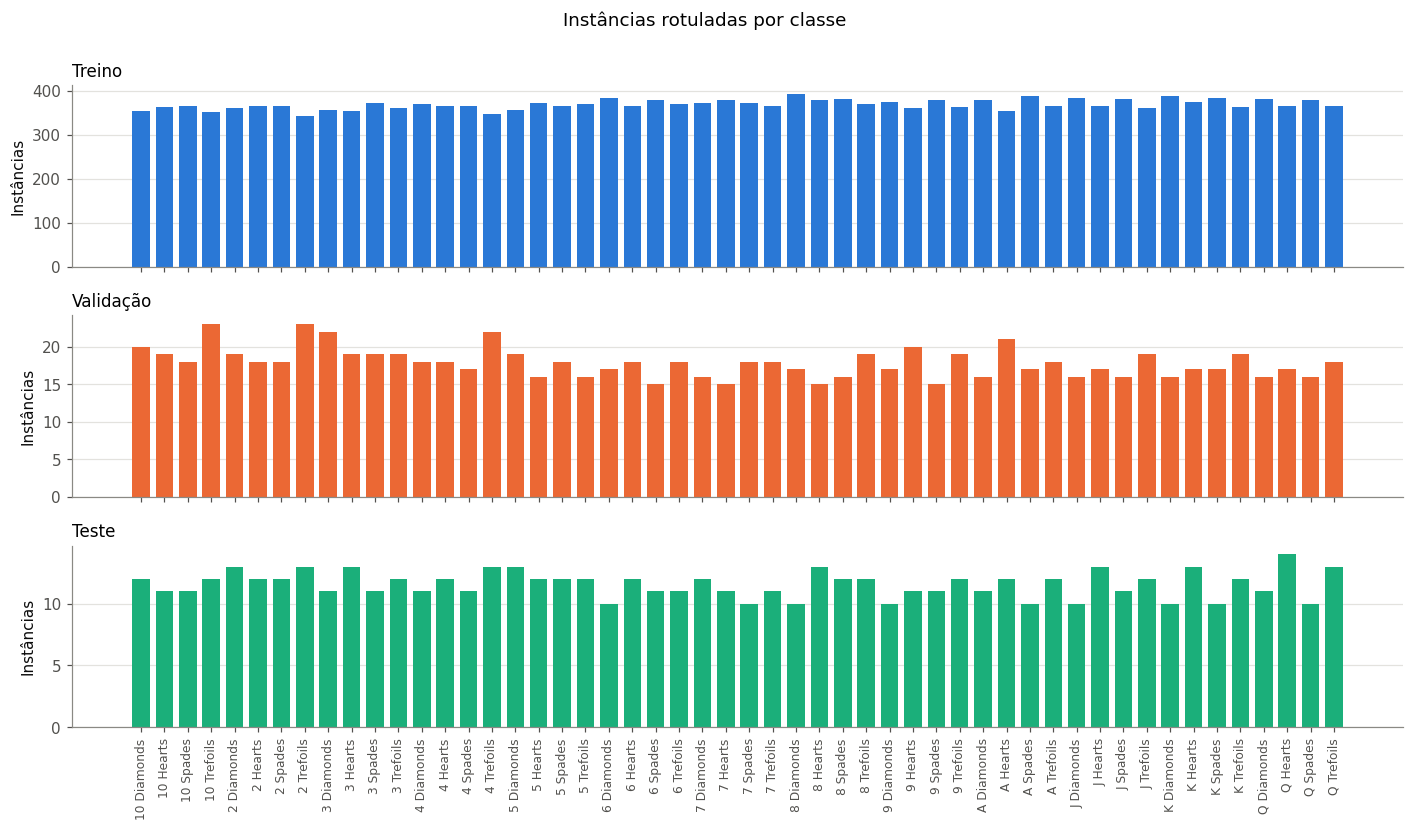

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 2.4))
for i, s in enumerate(SPLITS):
    n = info[s]["imagens"]
    ax.barh(i, n, color=COR[s], height=0.6)
    ax.text(n + tot_img * 0.01, i, f"{n:,} ({100*n/tot_img:.1f}%)".replace(",", "X").replace(".", ",").replace("X", "."), va="center", color="#0b0b0b")
ax.set_yticks(range(3), [NOME[s] for s in SPLITS]); ax.invert_yaxis()
ax.set_xlabel("Imagens"); ax.set_xlim(0, tot_img * 1.18); ax.grid(axis="y", visible=False)
ax.set_title("Divisão do dataset entre treino, validação e teste")
salvar(fig, "01_divisao_dataset.png"); plt.show()

fig, axs = plt.subplots(3, 1, figsize=(13, 7.5), sharex=True)
x = np.arange(len(NOMES))
for ax, s in zip(axs, SPLITS):
    ax.bar(x, por_classe[f"Instâncias ({NOME[s]})"], color=COR[s], width=0.75)
    ax.set_ylabel("Instâncias"); ax.set_title(NOME[s], loc="left"); ax.grid(axis="x", visible=False)
axs[-1].set_xticks(x, NOMES, rotation=90, fontsize=8)
fig.suptitle("Instâncias rotuladas por classe", y=1.0)
fig.tight_layout()
salvar(fig, "02_instancias_por_classe.png"); plt.show()

In [11]:
if TREINAR:
    model = YOLO(MODEL)
    model.train(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMG_SIZE, batch=BATCH, seed=SEED,
                plots=True, project=str(SAIDA), name="treino", exist_ok=True)
    PESOS = SAIDA / "treino" / "weights" / "best.pt"
else:
    PESOS = Path(PESOS_EXISTENTES)
    assert PESOS.exists(), "Defina PESOS_EXISTENTES com o caminho do best.pt"
print("Pesos usados na avaliação:", PESOS)

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/Cartas-Poker-4/data_tcc.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=treino, nbs=64, nms=None, opset=None, optimi

Figura salva: /content/drive/MyDrive/TCC_YOLO/yolov8n_50ep/figuras/03_curvas_perda.png


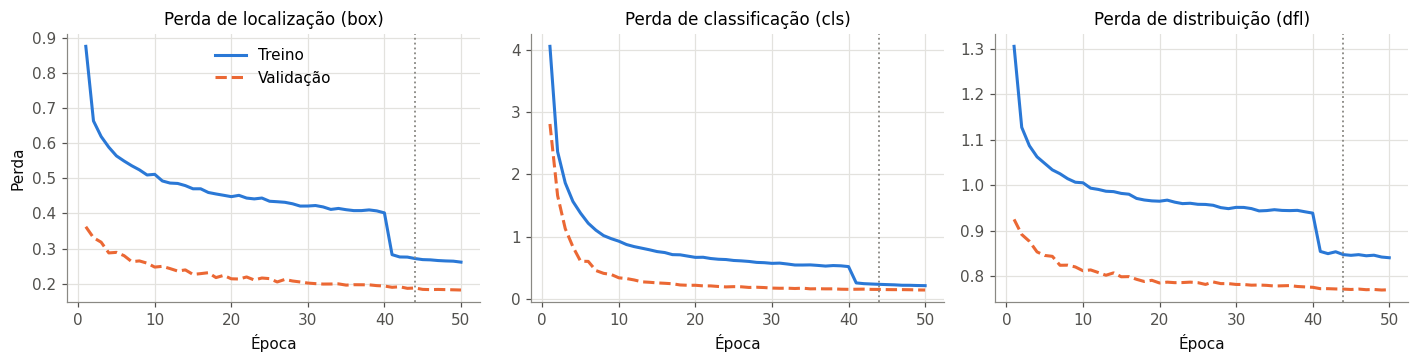

Figura salva: /content/drive/MyDrive/TCC_YOLO/yolov8n_50ep/figuras/04_metricas_por_epoca.png


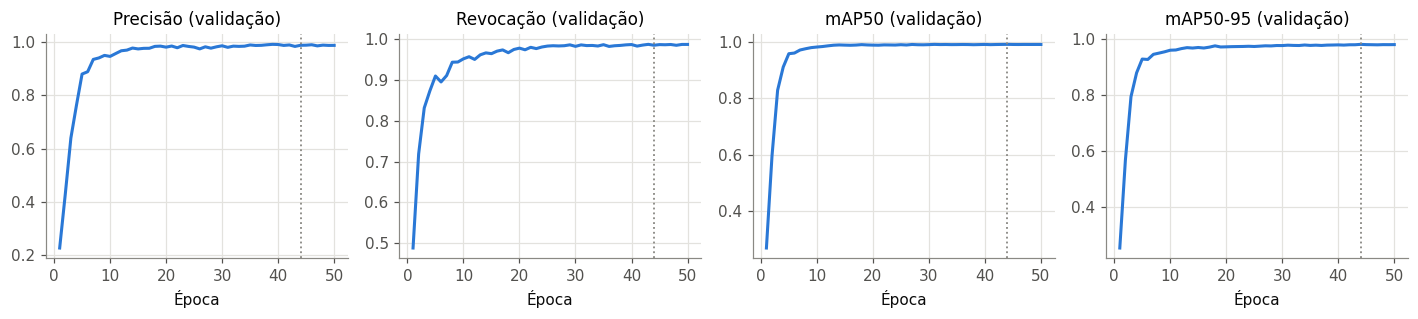

Época do best.pt: 44 de 50


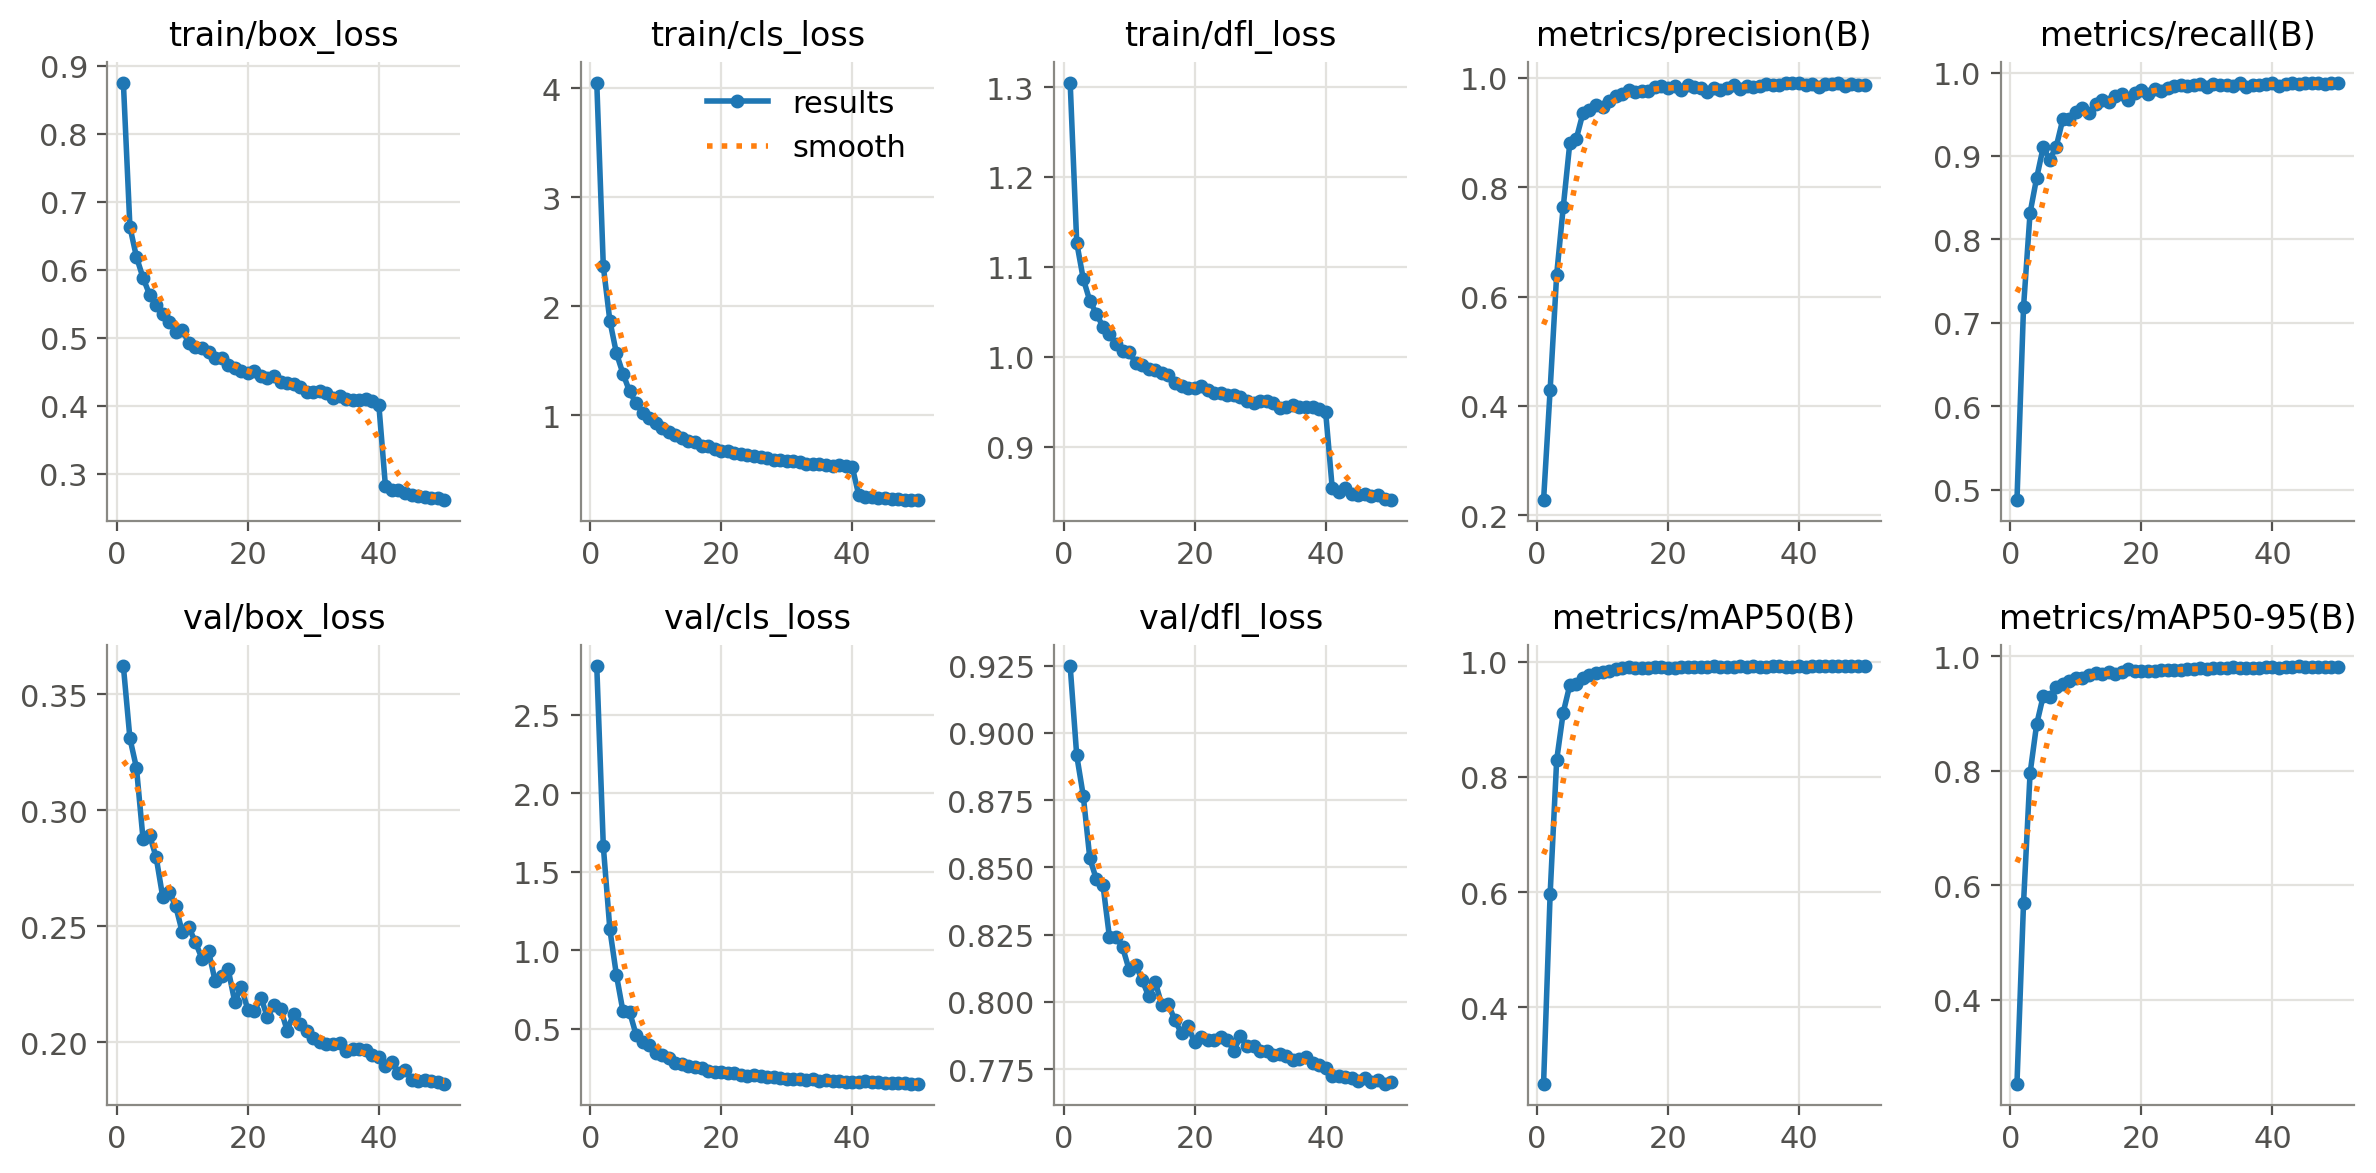

In [12]:
csv_res = SAIDA / "treino" / "results.csv"
if csv_res.exists():
    hist = pd.read_csv(csv_res); hist.columns = [c.strip() for c in hist.columns]
    hist.to_csv(TABELAS / "historico_treino.csv", index=False, sep=";", decimal=",")
    ep = hist["epoch"]
    fit = 0.1 * hist["metrics/mAP50(B)"] + 0.9 * hist["metrics/mAP50-95(B)"]
    melhor = int(ep[fit.idxmax()])

    fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
    for ax, perda, titulo in zip(axs, ["box_loss", "cls_loss", "dfl_loss"],
                                 ["Perda de localização (box)", "Perda de classificação (cls)", "Perda de distribuição (dfl)"]):
        ax.plot(ep, hist[f"train/{perda}"], color=COR["train"], lw=2, label="Treino")
        ax.plot(ep, hist[f"val/{perda}"], color=COR["val"], lw=2, ls="--", label="Validação")
        ax.axvline(melhor, color="#8a8984", ls=":", lw=1.2)
        ax.set_title(titulo); ax.set_xlabel("Época")
    axs[0].set_ylabel("Perda"); axs[0].legend()
    fig.tight_layout(); salvar(fig, "03_curvas_perda.png"); plt.show()

    fig, axs = plt.subplots(1, 4, figsize=(13, 3.0), sharey=False)
    for ax, col, titulo in zip(axs, ["metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)"],
                               ["Precisão", "Revocação", "mAP50", "mAP50-95"]):
        ax.plot(ep, hist[col], color=COR["train"], lw=2)
        ax.axvline(melhor, color="#8a8984", ls=":", lw=1.2)
        ax.set_title(f"{titulo} (validação)"); ax.set_xlabel("Época")
    fig.tight_layout(); salvar(fig, "04_metricas_por_epoca.png"); plt.show()
    print(f"Época do best.pt: {melhor} de {int(ep.max())}")
    display(IPImage(filename=str(SAIDA / "treino" / "results.png"), width=900))
else:
    print("results.csv não encontrado (pesos treinados em outra sessão): curvas de treino indisponíveis.")

In [13]:
modelo_av = YOLO(str(PESOS))
metricas, por_classe_metr, conf_stats = {}, {}, {}

for s in SPLITS:
    print(f"\n===== {NOME[s]} =====")
    m = modelo_av.val(data=str(DATA_YAML), split=s, imgsz=IMG_SIZE, batch=BATCH, plots=True,
                      project=str(SAIDA / "avaliacao"), name=s, exist_ok=True)
    b = m.box
    mp, mr = float(b.mp), float(b.mr)
    metricas[s] = {"P": mp, "R": mr, "F1": 2 * mp * mr / (mp + mr) if mp + mr else 0.0,
                   "mAP50": float(b.map50), "mAP50-95": float(b.map),
                   "ms/imagem (inferência)": float(m.speed.get("inference", np.nan)),
                   "pasta": str(m.save_dir)}

    idx = list(b.ap_class_index)
    por_classe_metr[s] = pd.DataFrame({
        "Classe": [NOMES[i] for i in idx], "P": b.p, "R": b.r,
        "mAP50": b.ap50, "mAP50-95": b.ap,
    })

    cm = getattr(m, "confusion_matrix", None)
    if cm is not None:
        M = np.asarray(cm.matrix); nc = len(NOMES)
        certos = np.trace(M[:nc, :nc]); trocas = M[:nc, :nc].sum() - certos
        conf_stats[s] = {"Detecções corretas": int(certos), "Cartas trocadas": int(trocas),
                         "% cartas trocadas": 100 * trocas / max(1, certos + trocas),
                         "Falsos positivos (fundo)": int(M[:nc, nc].sum()),
                         "Cartas não detectadas": int(M[nc, :nc].sum())}


===== Treino =====
Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,145,100 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 923.4±536.7 MB/s, size: 15.4 KB)
val: Scanning /content/datasets/Cartas-Poker-4/train/labels.cache... 6285 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 6285/6285 2.4Git/s 0.0s
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 18861, len(boxes) = 19182. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 393/393 6.6it/s 59.6s
                   all       6285      19182      0.991       0.99      0.994      0.971
           10 Diamonds        354        354      0.996      0.989      0.995      0.919

In [14]:
resumo = pd.DataFrame([{
    "Conjunto": NOME[s],
    "Imagens": info[s]["imagens"],
    "% do dataset": 100 * info[s]["imagens"] / tot_img,
    "Instâncias": info[s]["instancias"],
    **{k: metricas[s][k] for k in ["P", "R", "F1", "mAP50", "mAP50-95", "ms/imagem (inferência)"]},
} for s in SPLITS])
resumo.to_csv(TABELAS / "metricas_por_conjunto.csv", index=False, sep=";", decimal=",")
display(resumo.style.format({"% do dataset": "{:.1f}%", "P": "{:.3f}", "R": "{:.3f}", "F1": "{:.3f}",
                             "mAP50": "{:.3f}", "mAP50-95": "{:.3f}", "ms/imagem (inferência)": "{:.1f}"}).hide(axis="index"))

if conf_stats:
    confusao = pd.DataFrame([{"Conjunto": NOME[s], **conf_stats[s]} for s in SPLITS if s in conf_stats])
    confusao.to_csv(TABELAS / "matriz_confusao_resumo.csv", index=False, sep=";", decimal=",")
    print("\nResumo da matriz de confusão (limiar de confiança padrão da matriz do Ultralytics):")
    display(confusao.style.format({"% cartas trocadas": "{:.2f}%"}).hide(axis="index"))

g = {k: metricas["train"][k] - metricas["test"][k] for k in ["P", "R", "mAP50", "mAP50-95"]}
print("\nDiferença treino − teste:", ", ".join(f"{k} {v:+.3f}" for k, v in g.items()))

with open(SAIDA / "metricas.json", "w") as f:
    json.dump({"modelo": MODEL, "epocas": EPOCHS, "metricas": metricas,
               "composicao": composicao.to_dict(orient="records")}, f, ensure_ascii=False, indent=2)

Conjunto,Imagens,% do dataset,Instâncias,P,R,F1,mAP50,mAP50-95,ms/imagem (inferência)
Treino,6285,93.2%,19182,0.991,0.990,0.991,0.994,0.971,4.1
Validação,283,4.2%,930,0.988,0.986,0.987,0.992,0.982,5.1
Teste,173,2.6%,602,0.990,0.984,0.987,0.994,0.984,4.6



Resumo da matriz de confusão (limiar de confiança padrão da matriz do Ultralytics):


Conjunto,Detecções corretas,Cartas trocadas,% cartas trocadas,Falsos positivos (fundo),Cartas não detectadas
Treino,19050,132,0.69%,63800,0
Validação,925,4,0.43%,2637,1
Teste,596,6,1.00%,1775,0



Diferença treino − teste: P +0.001, R +0.006, mAP50 -0.000, mAP50-95 -0.013


Figura salva: /content/drive/MyDrive/TCC_YOLO/yolov8n_50ep/figuras/05_metricas_por_conjunto.png


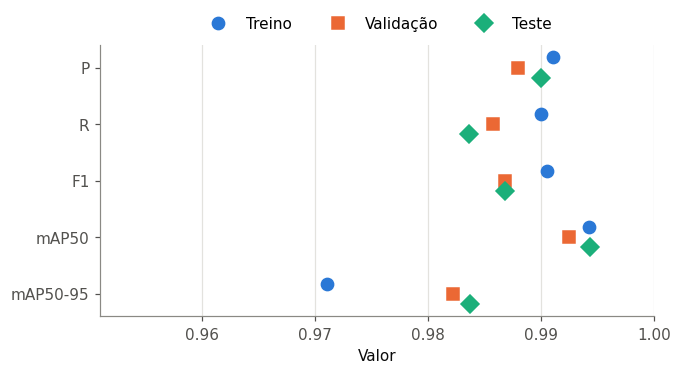

In [15]:
nomes_m = ["P", "R", "F1", "mAP50", "mAP50-95"]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
for k, s in enumerate(SPLITS):
    y = np.arange(len(nomes_m)) + (k - 1) * 0.18
    ax.plot([metricas[s][n] for n in nomes_m], y, MARCA[s], color=COR[s], ms=8, ls="none", label=NOME[s])
ax.set_yticks(range(len(nomes_m)), nomes_m); ax.invert_yaxis()
vmin = min(metricas[s][n] for s in SPLITS for n in nomes_m)
ax.set_xlim(max(0, vmin - 0.02), 1.0); ax.set_xlabel("Valor"); ax.grid(axis="y", visible=False)
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0))
salvar(fig, "05_metricas_por_conjunto.png"); plt.show()


----- Treino (/content/drive/MyDrive/TCC_YOLO/yolov8n_50ep/avaliacao/train) -----


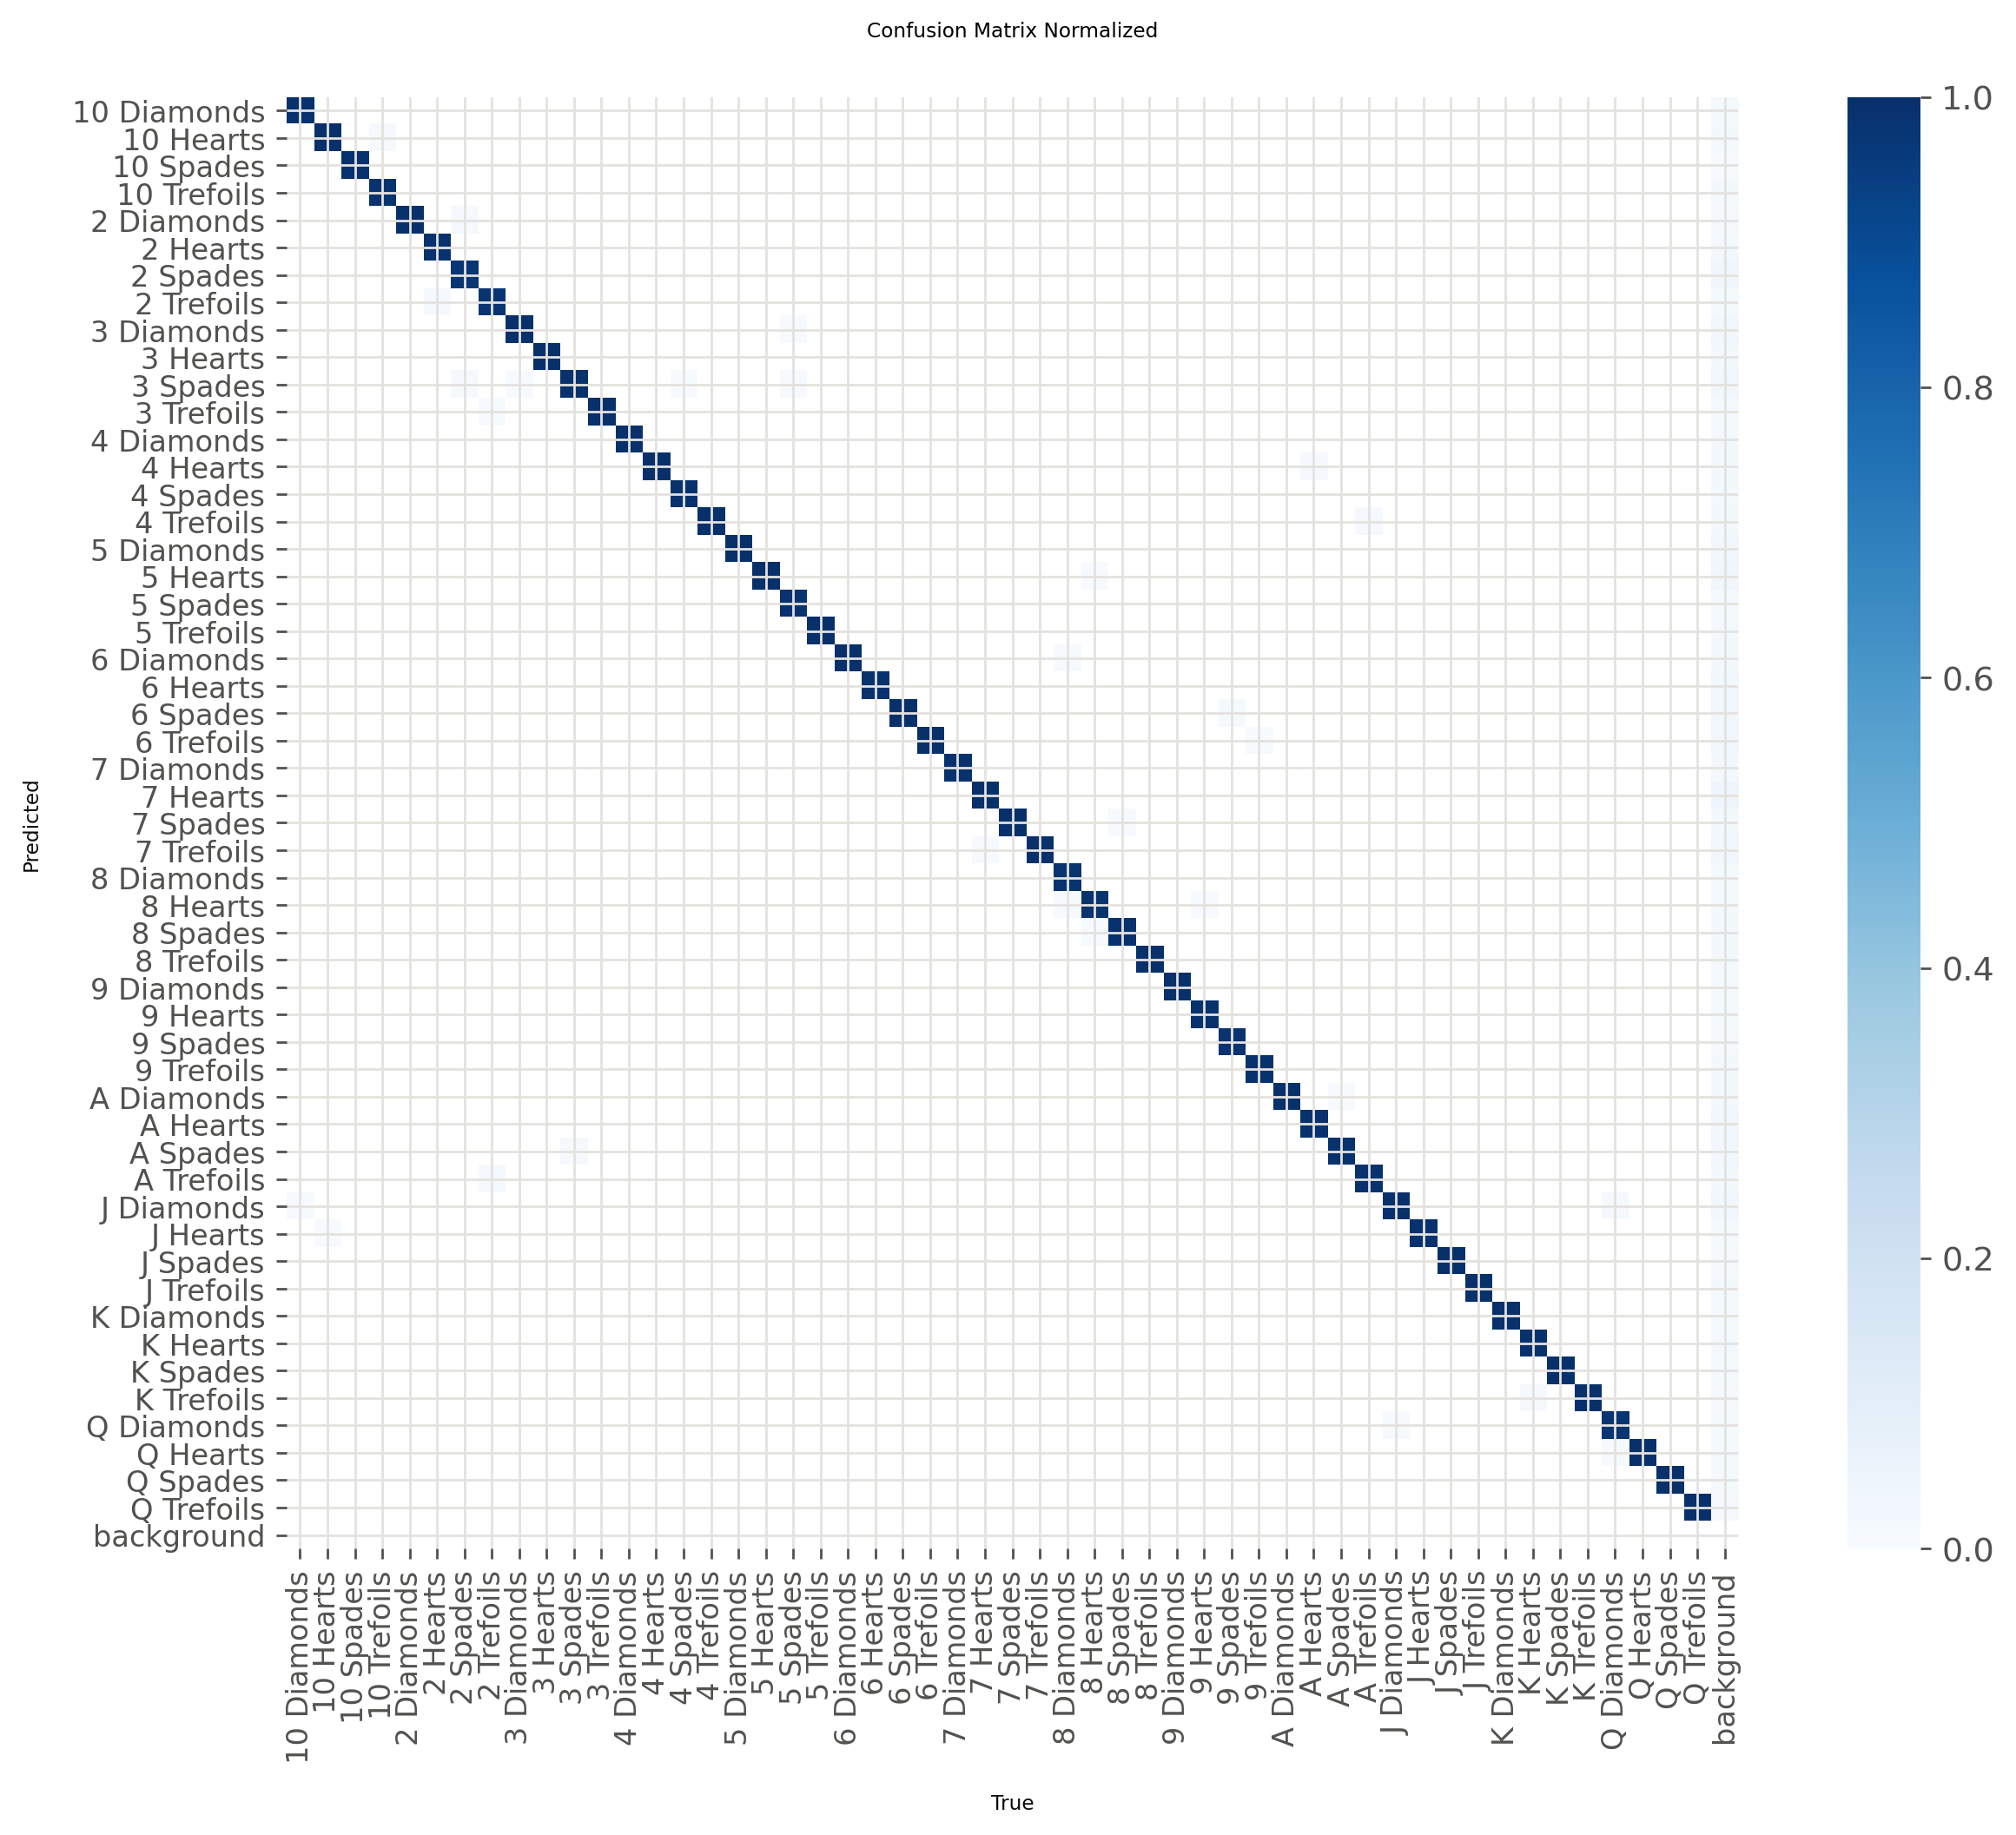

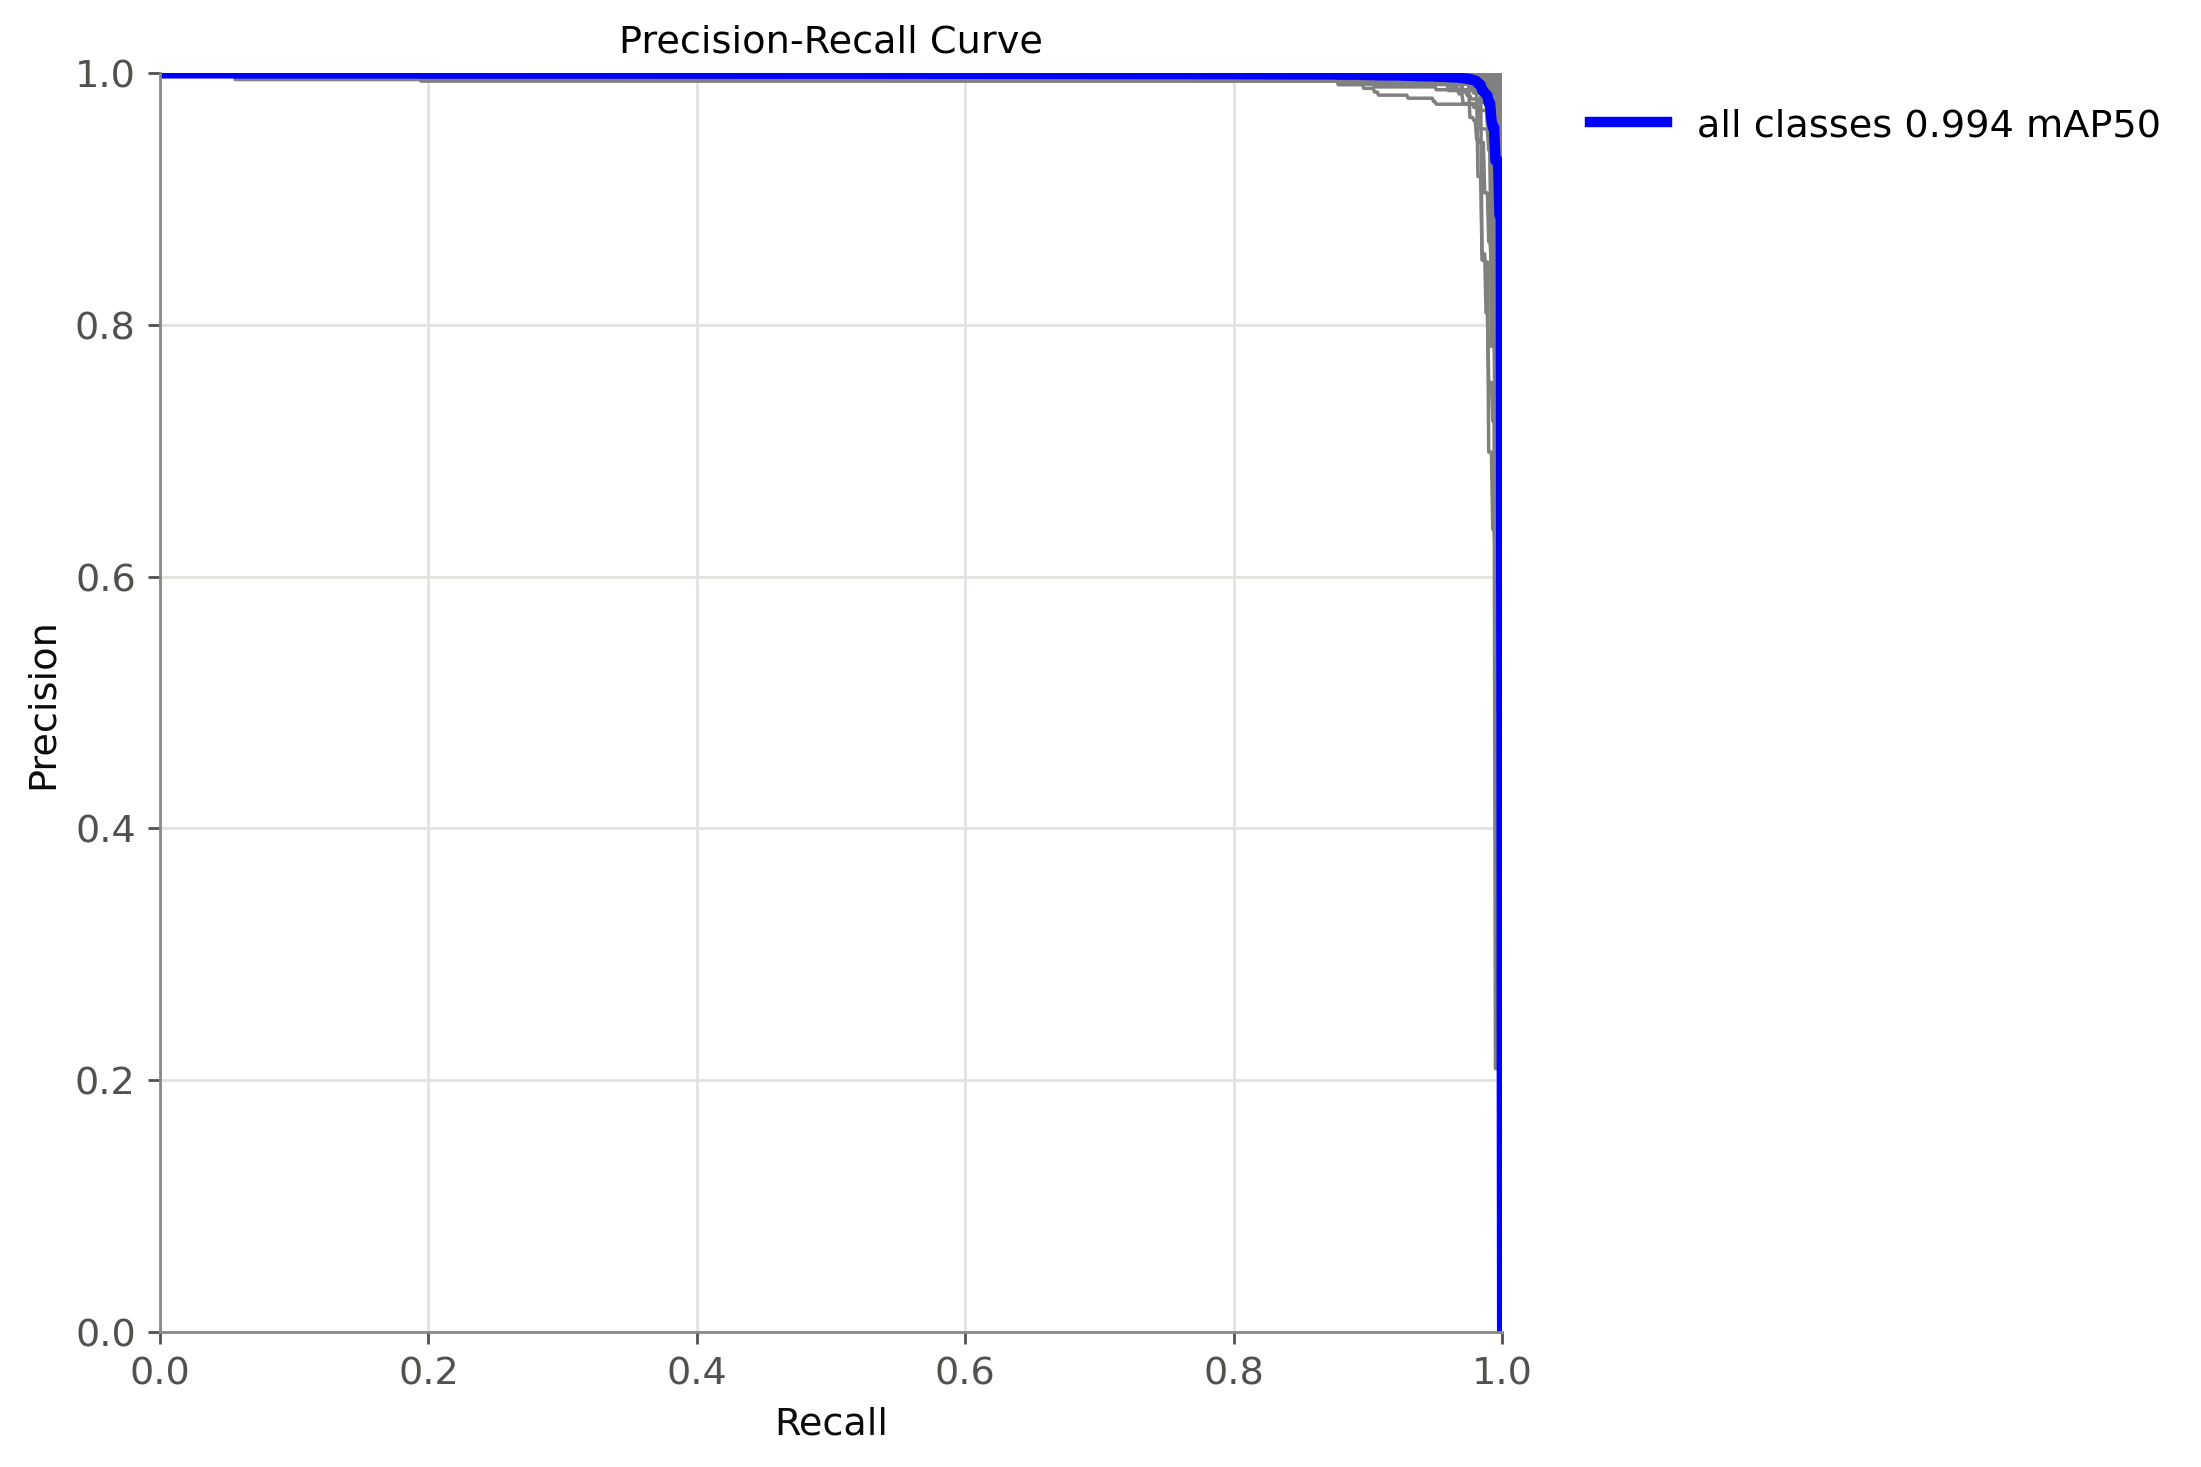

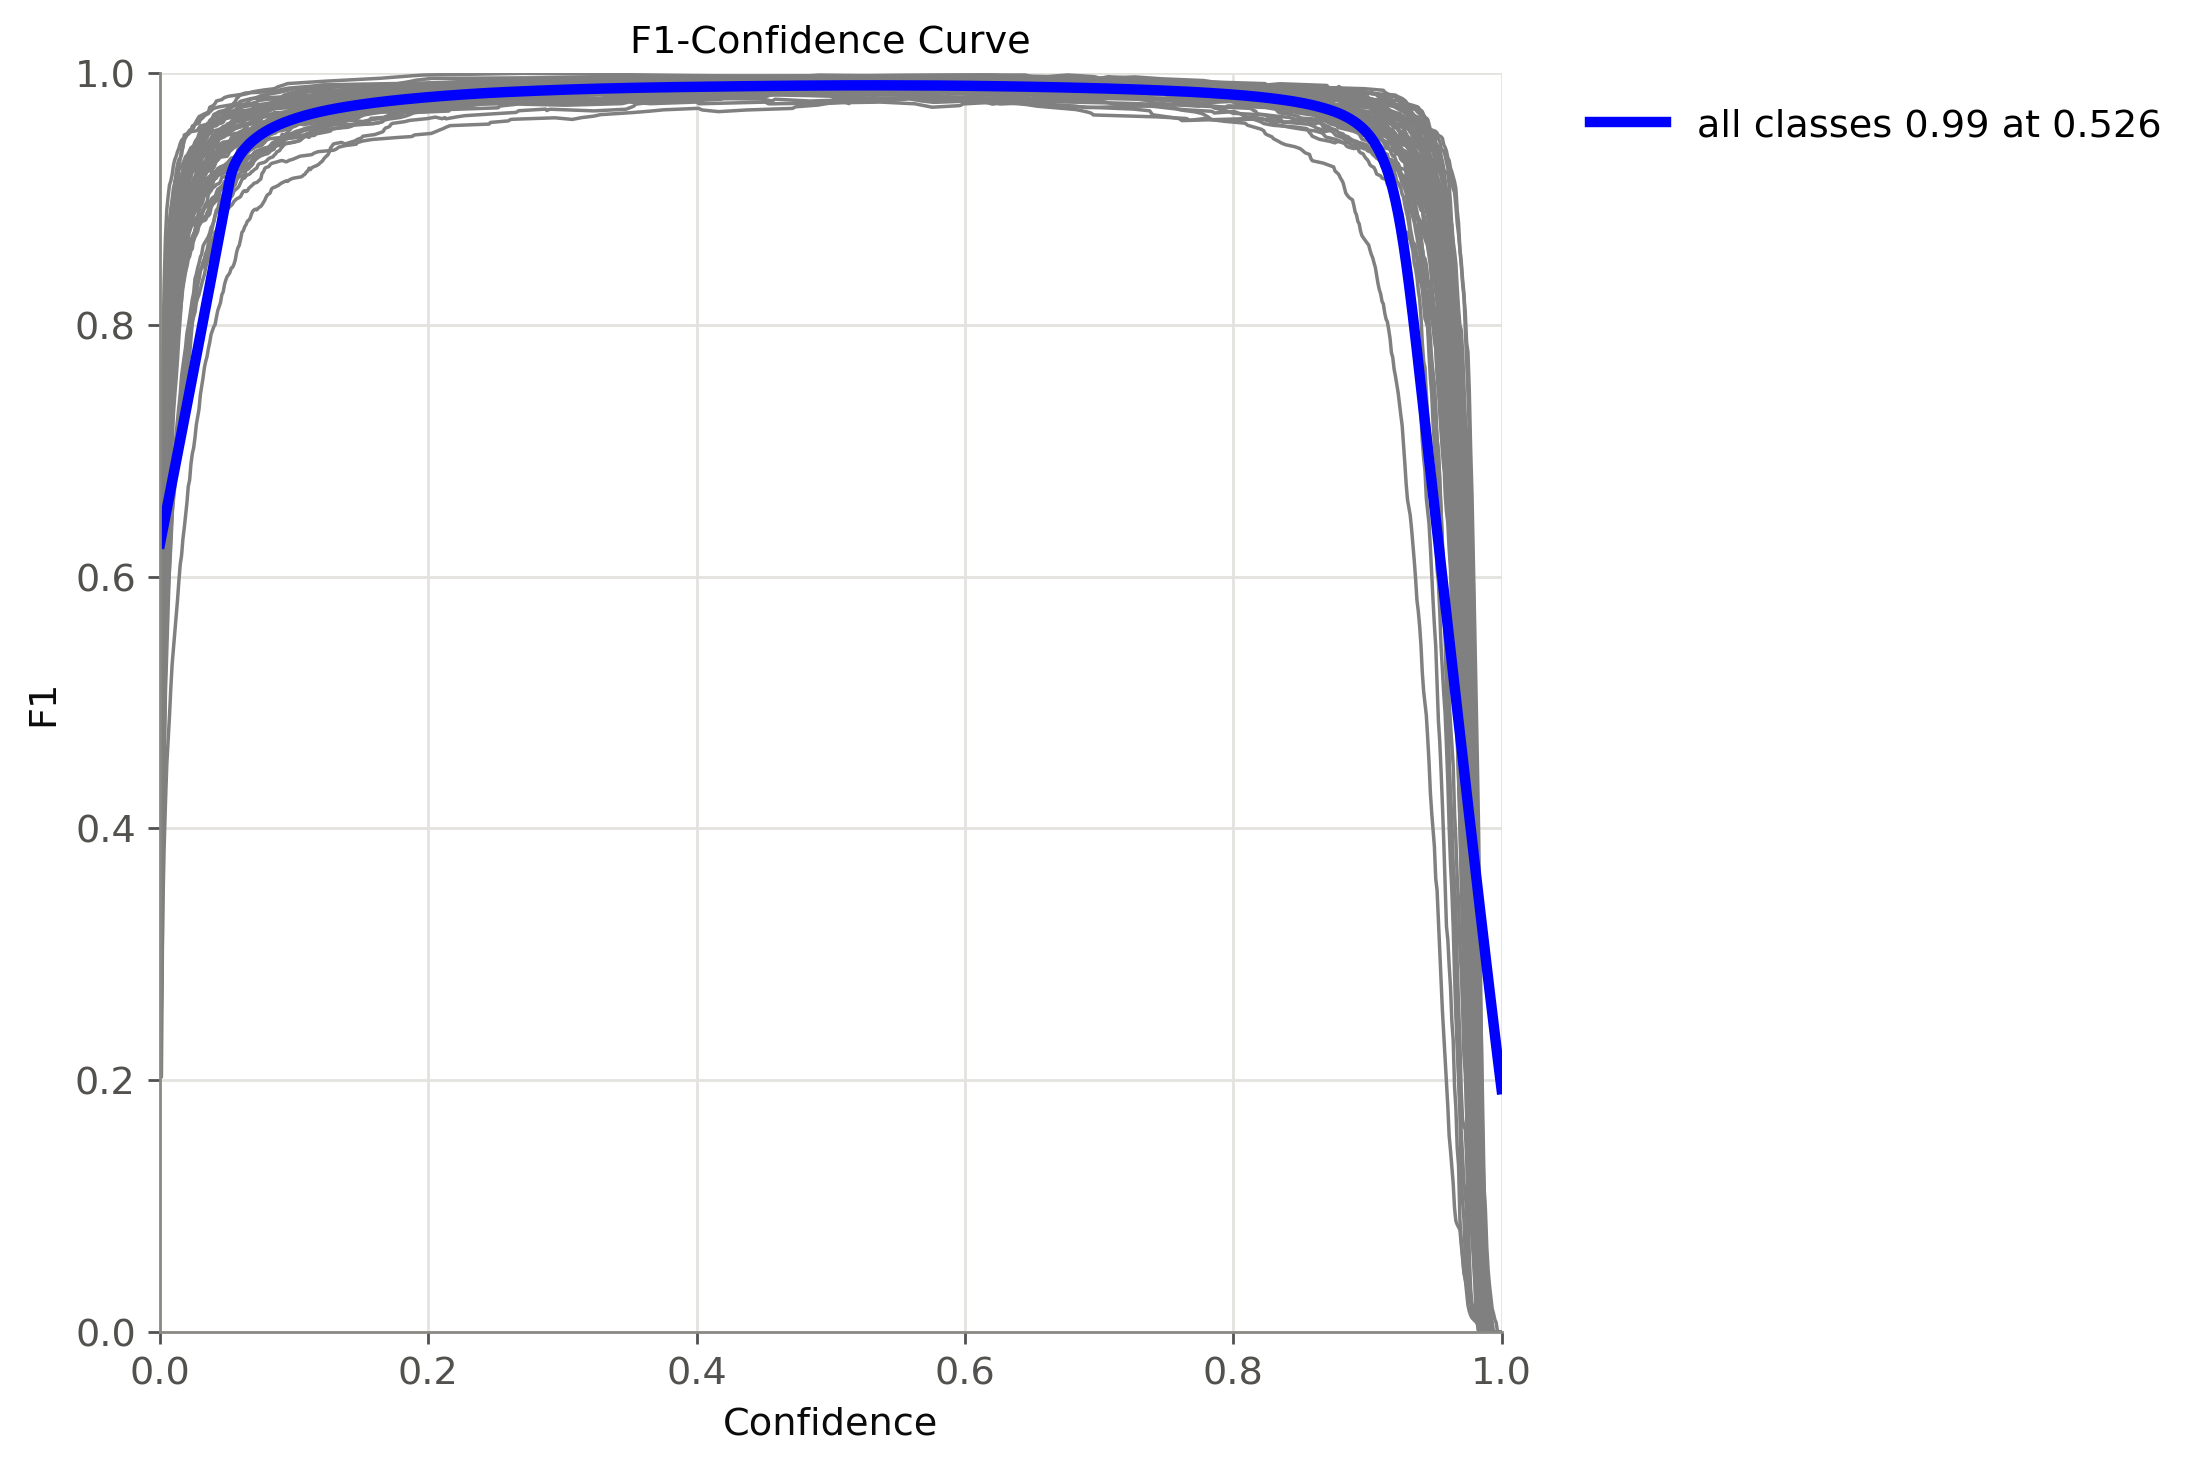


----- Validação (/content/drive/MyDrive/TCC_YOLO/yolov8n_50ep/avaliacao/val) -----


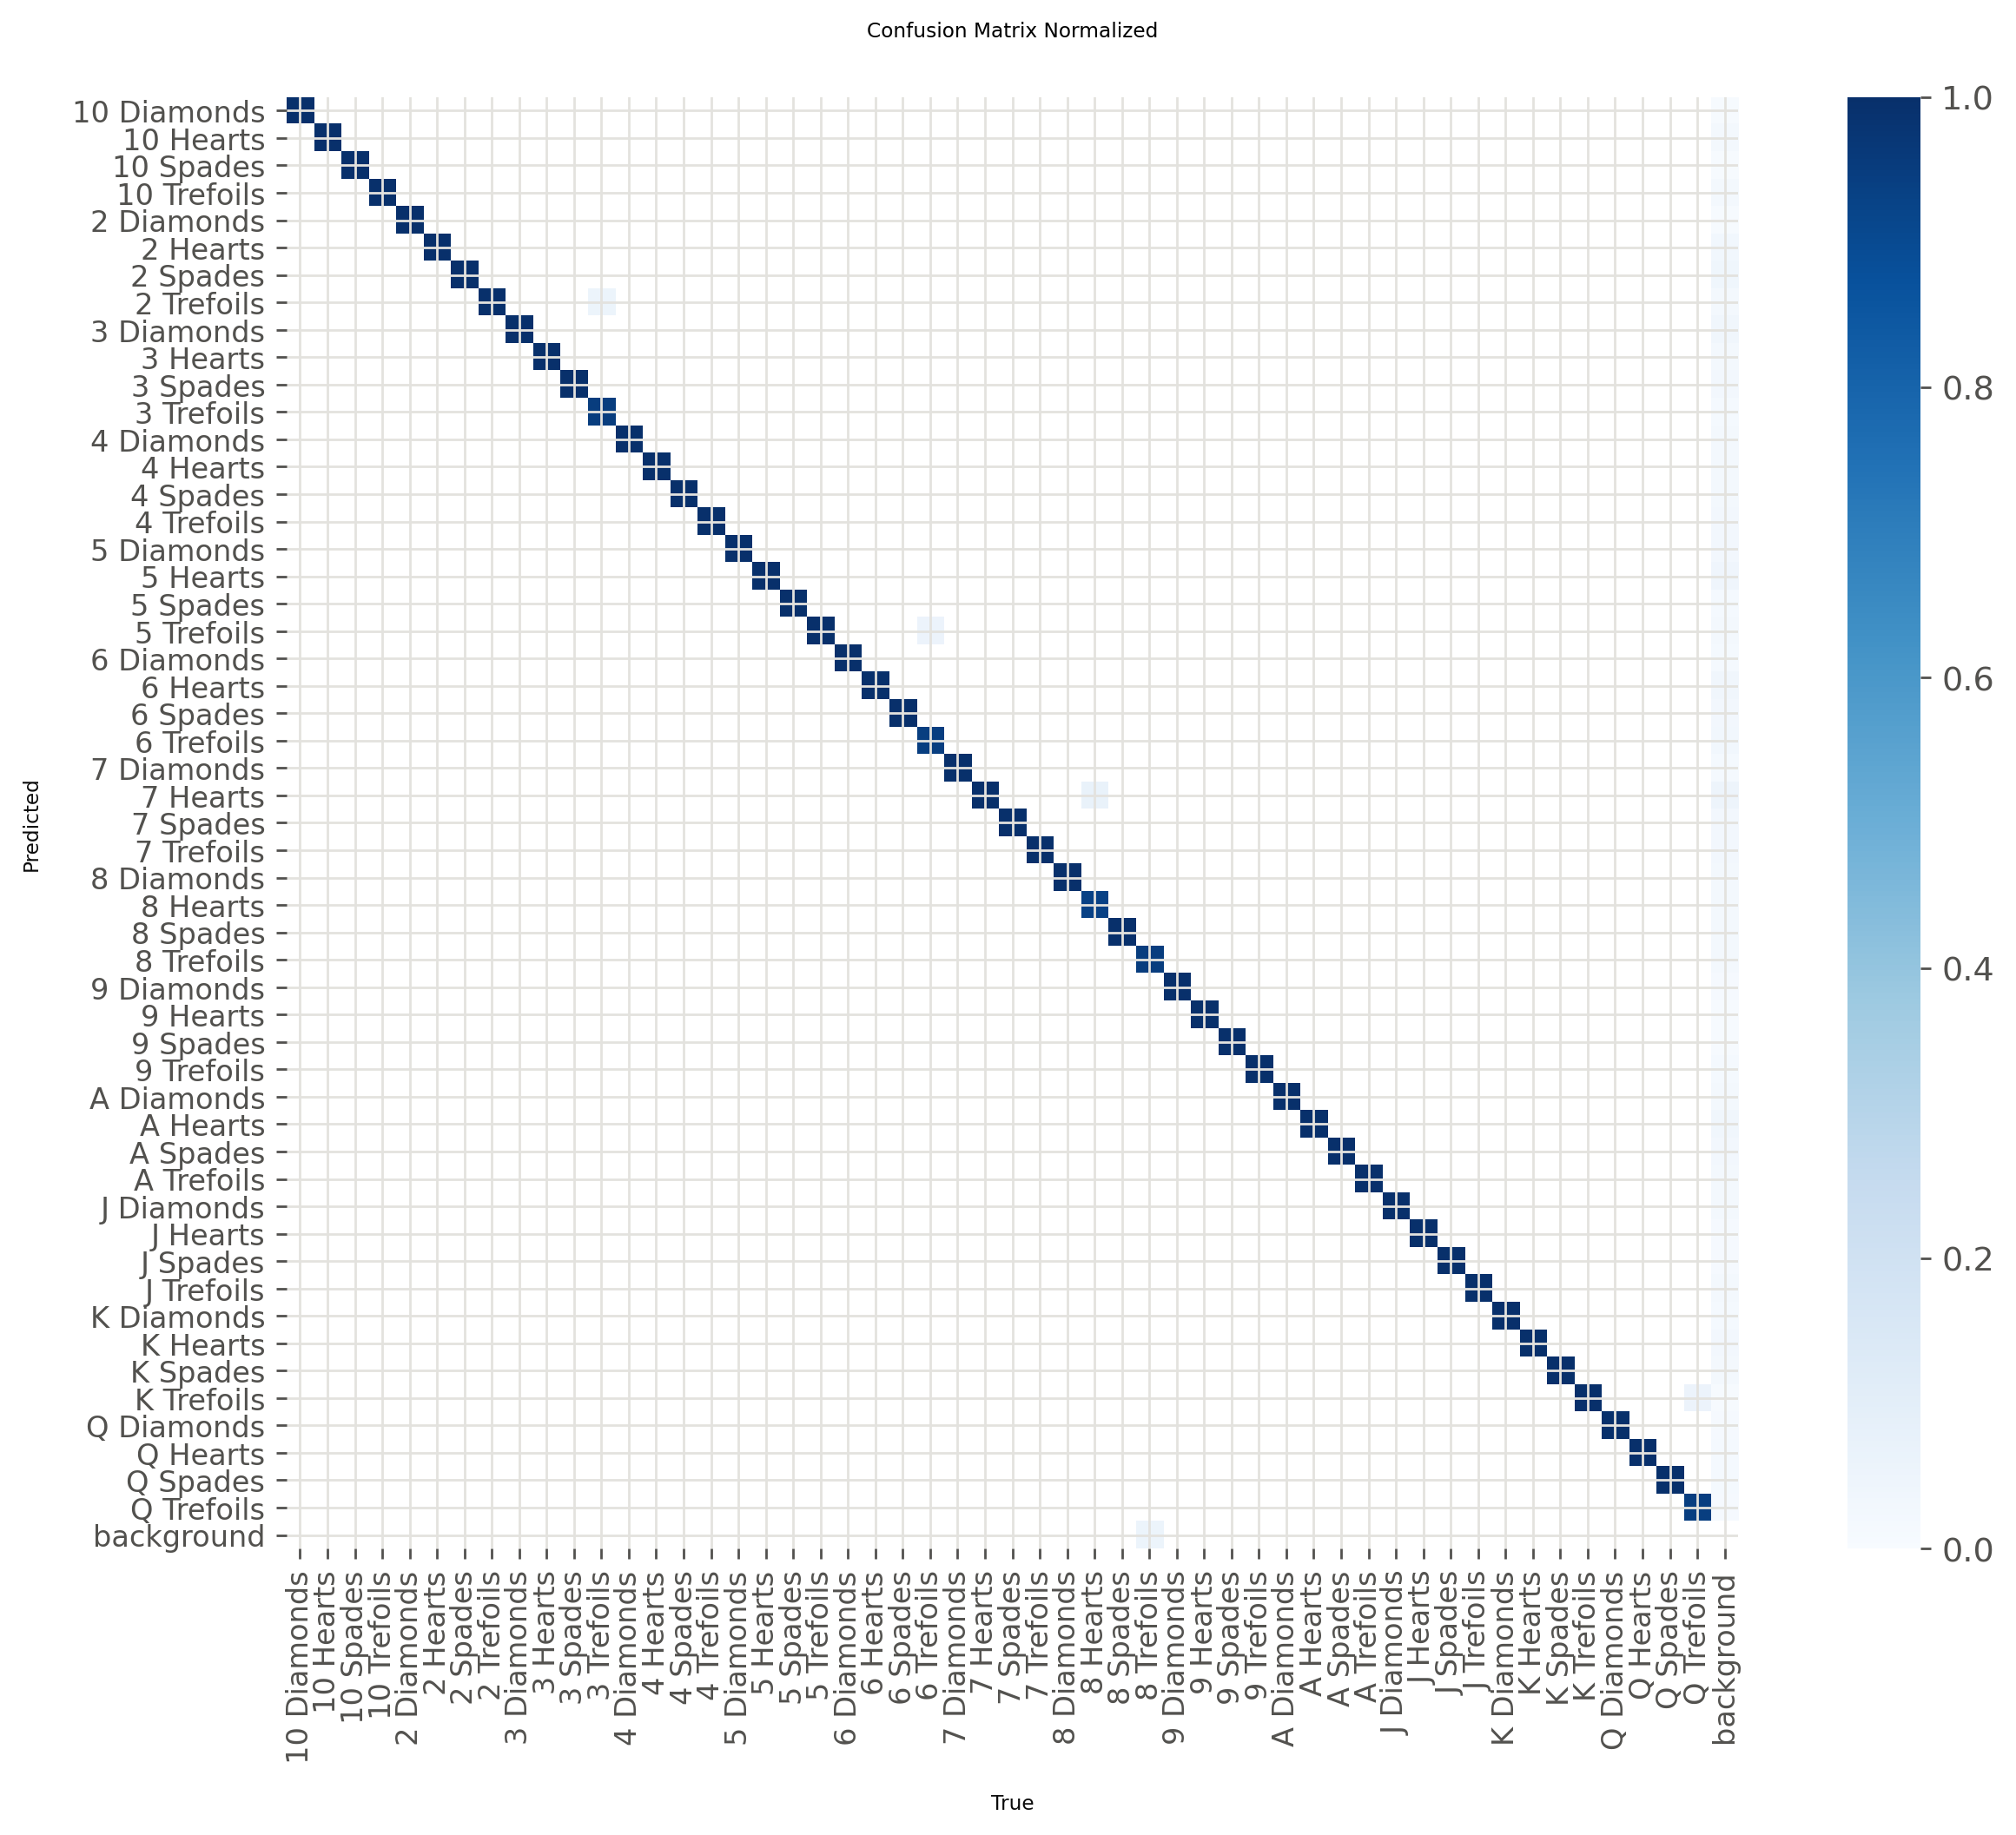

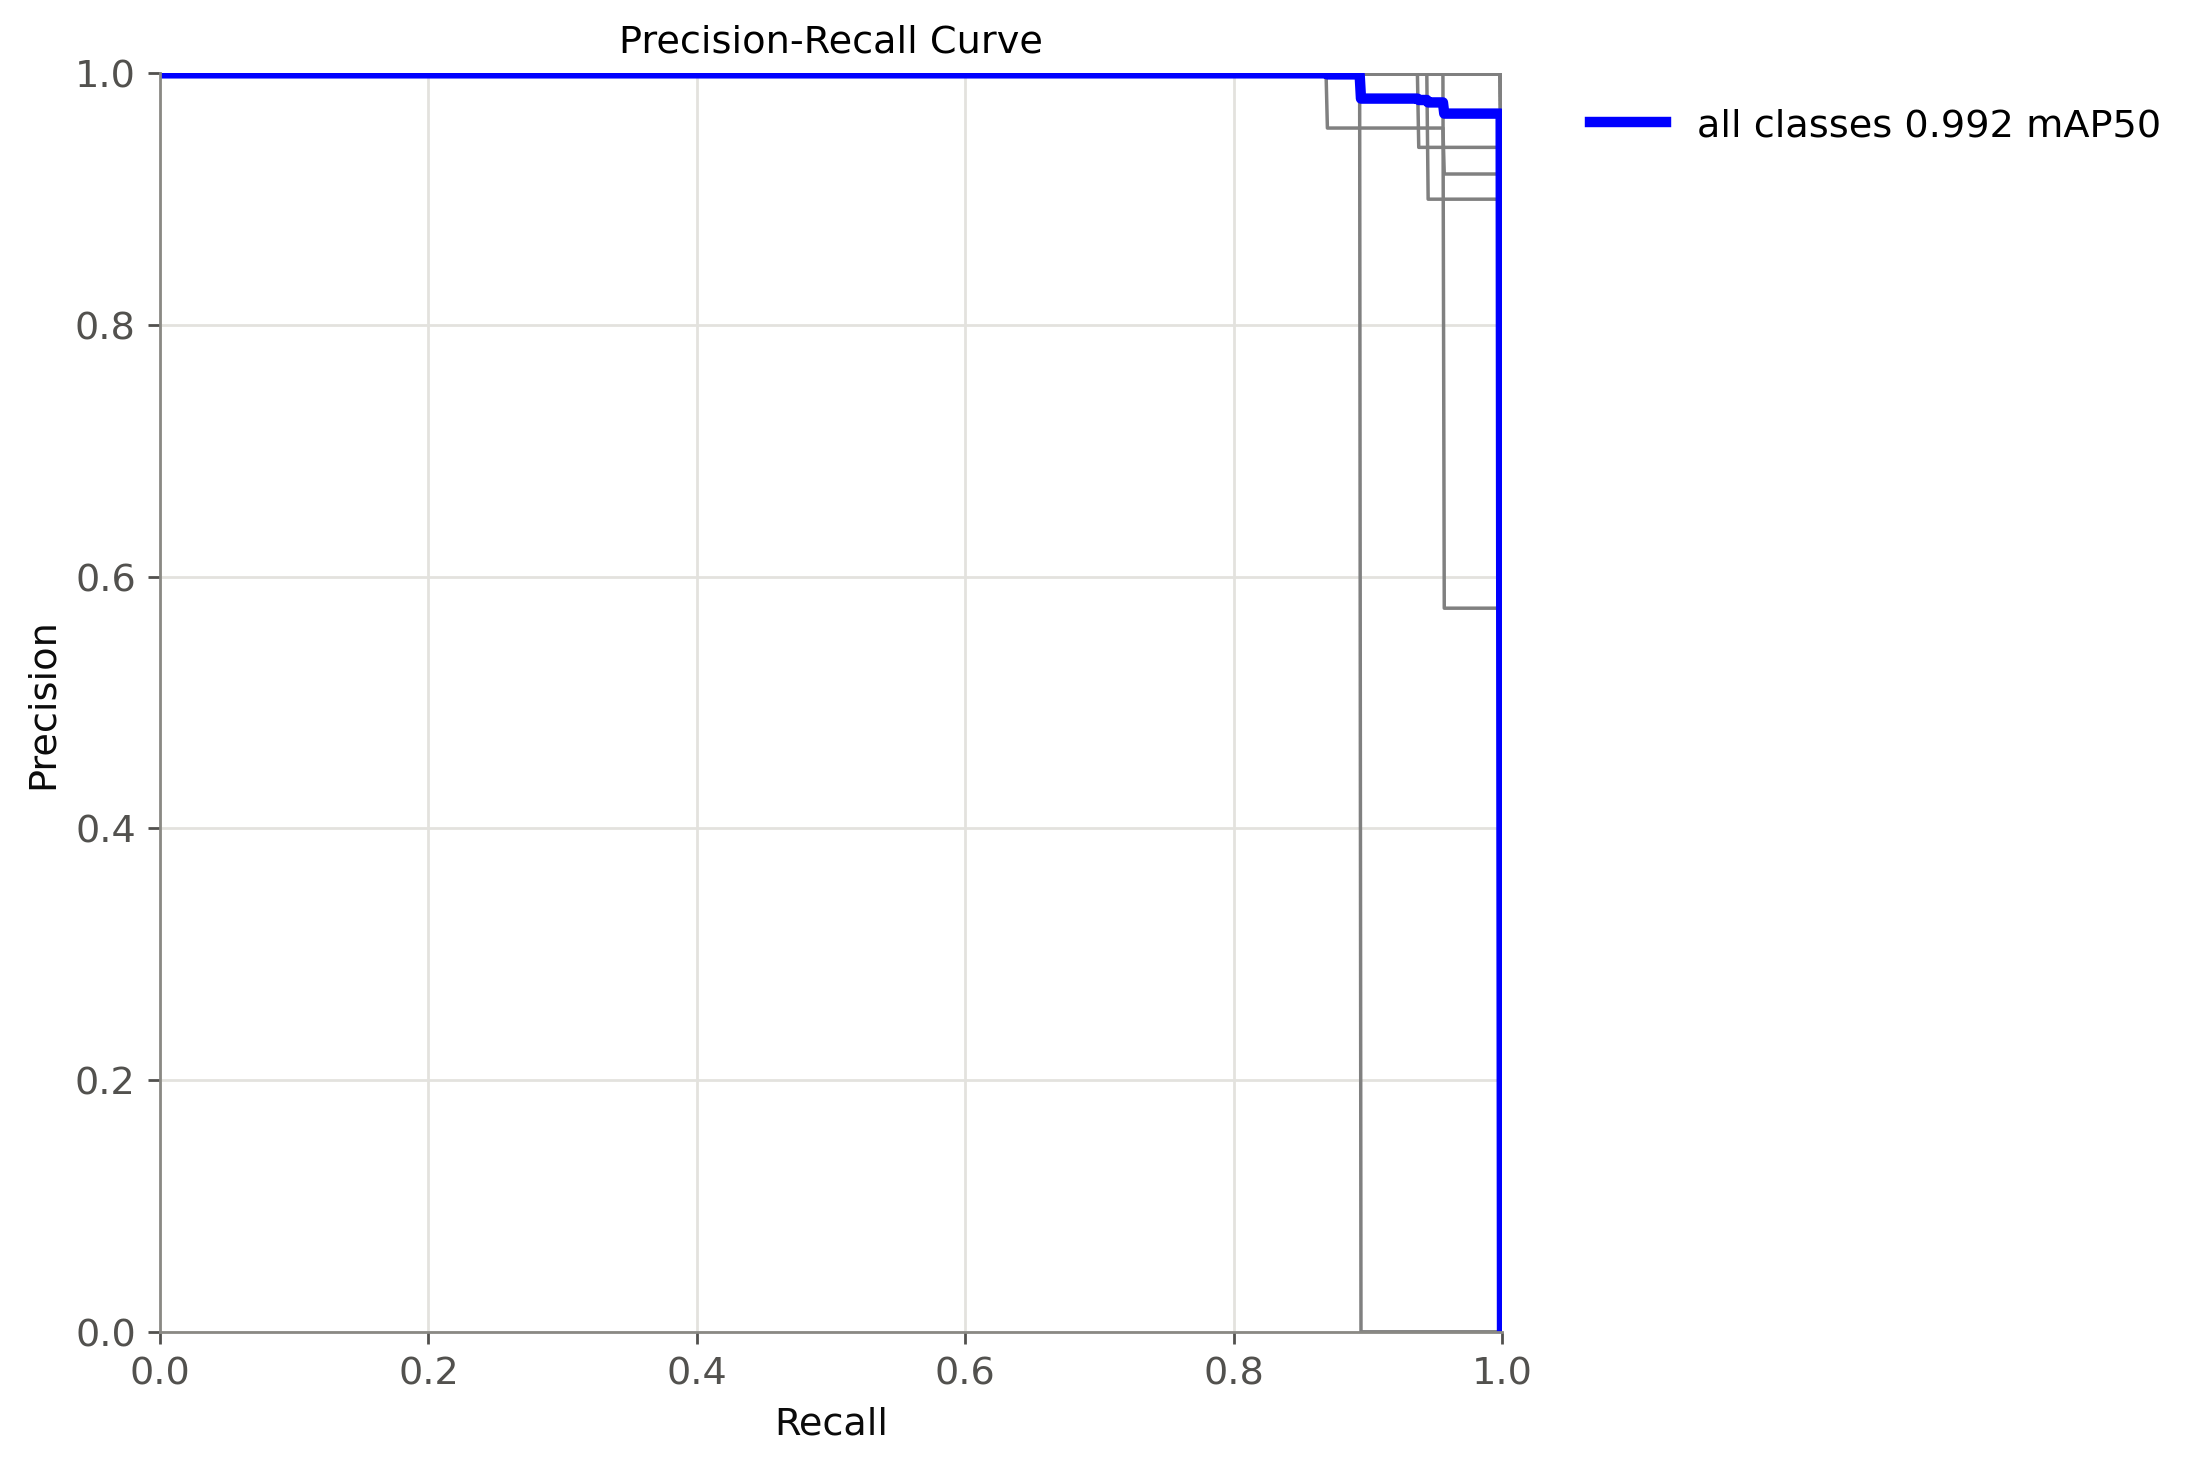

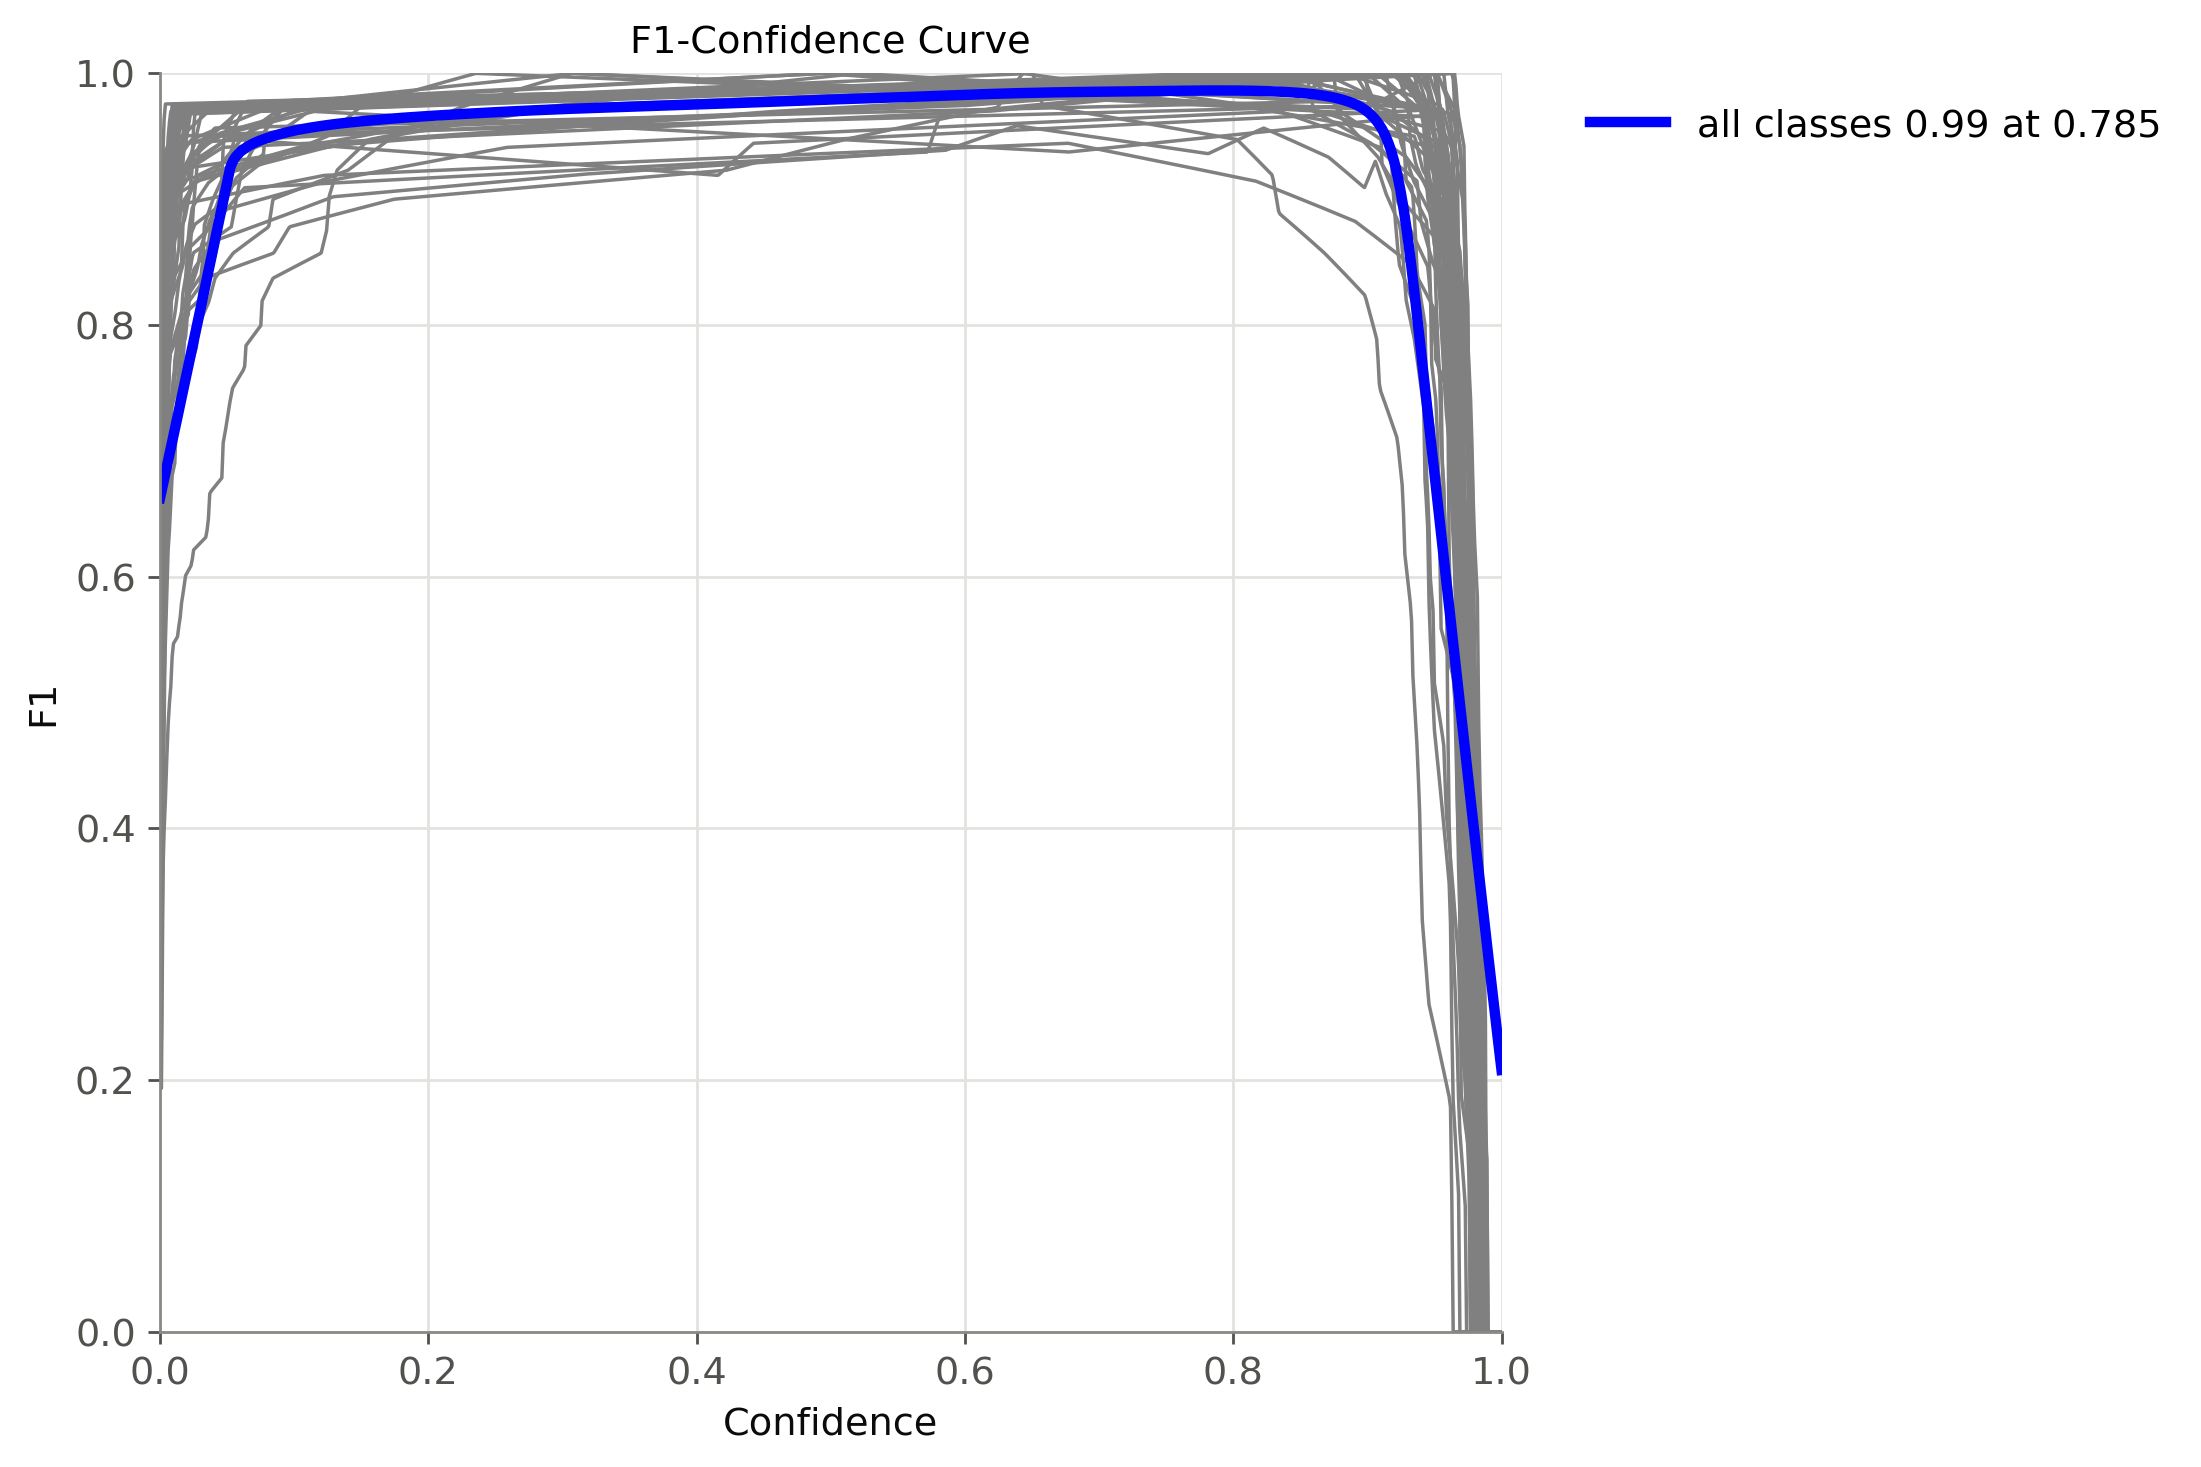


----- Teste (/content/drive/MyDrive/TCC_YOLO/yolov8n_50ep/avaliacao/test) -----


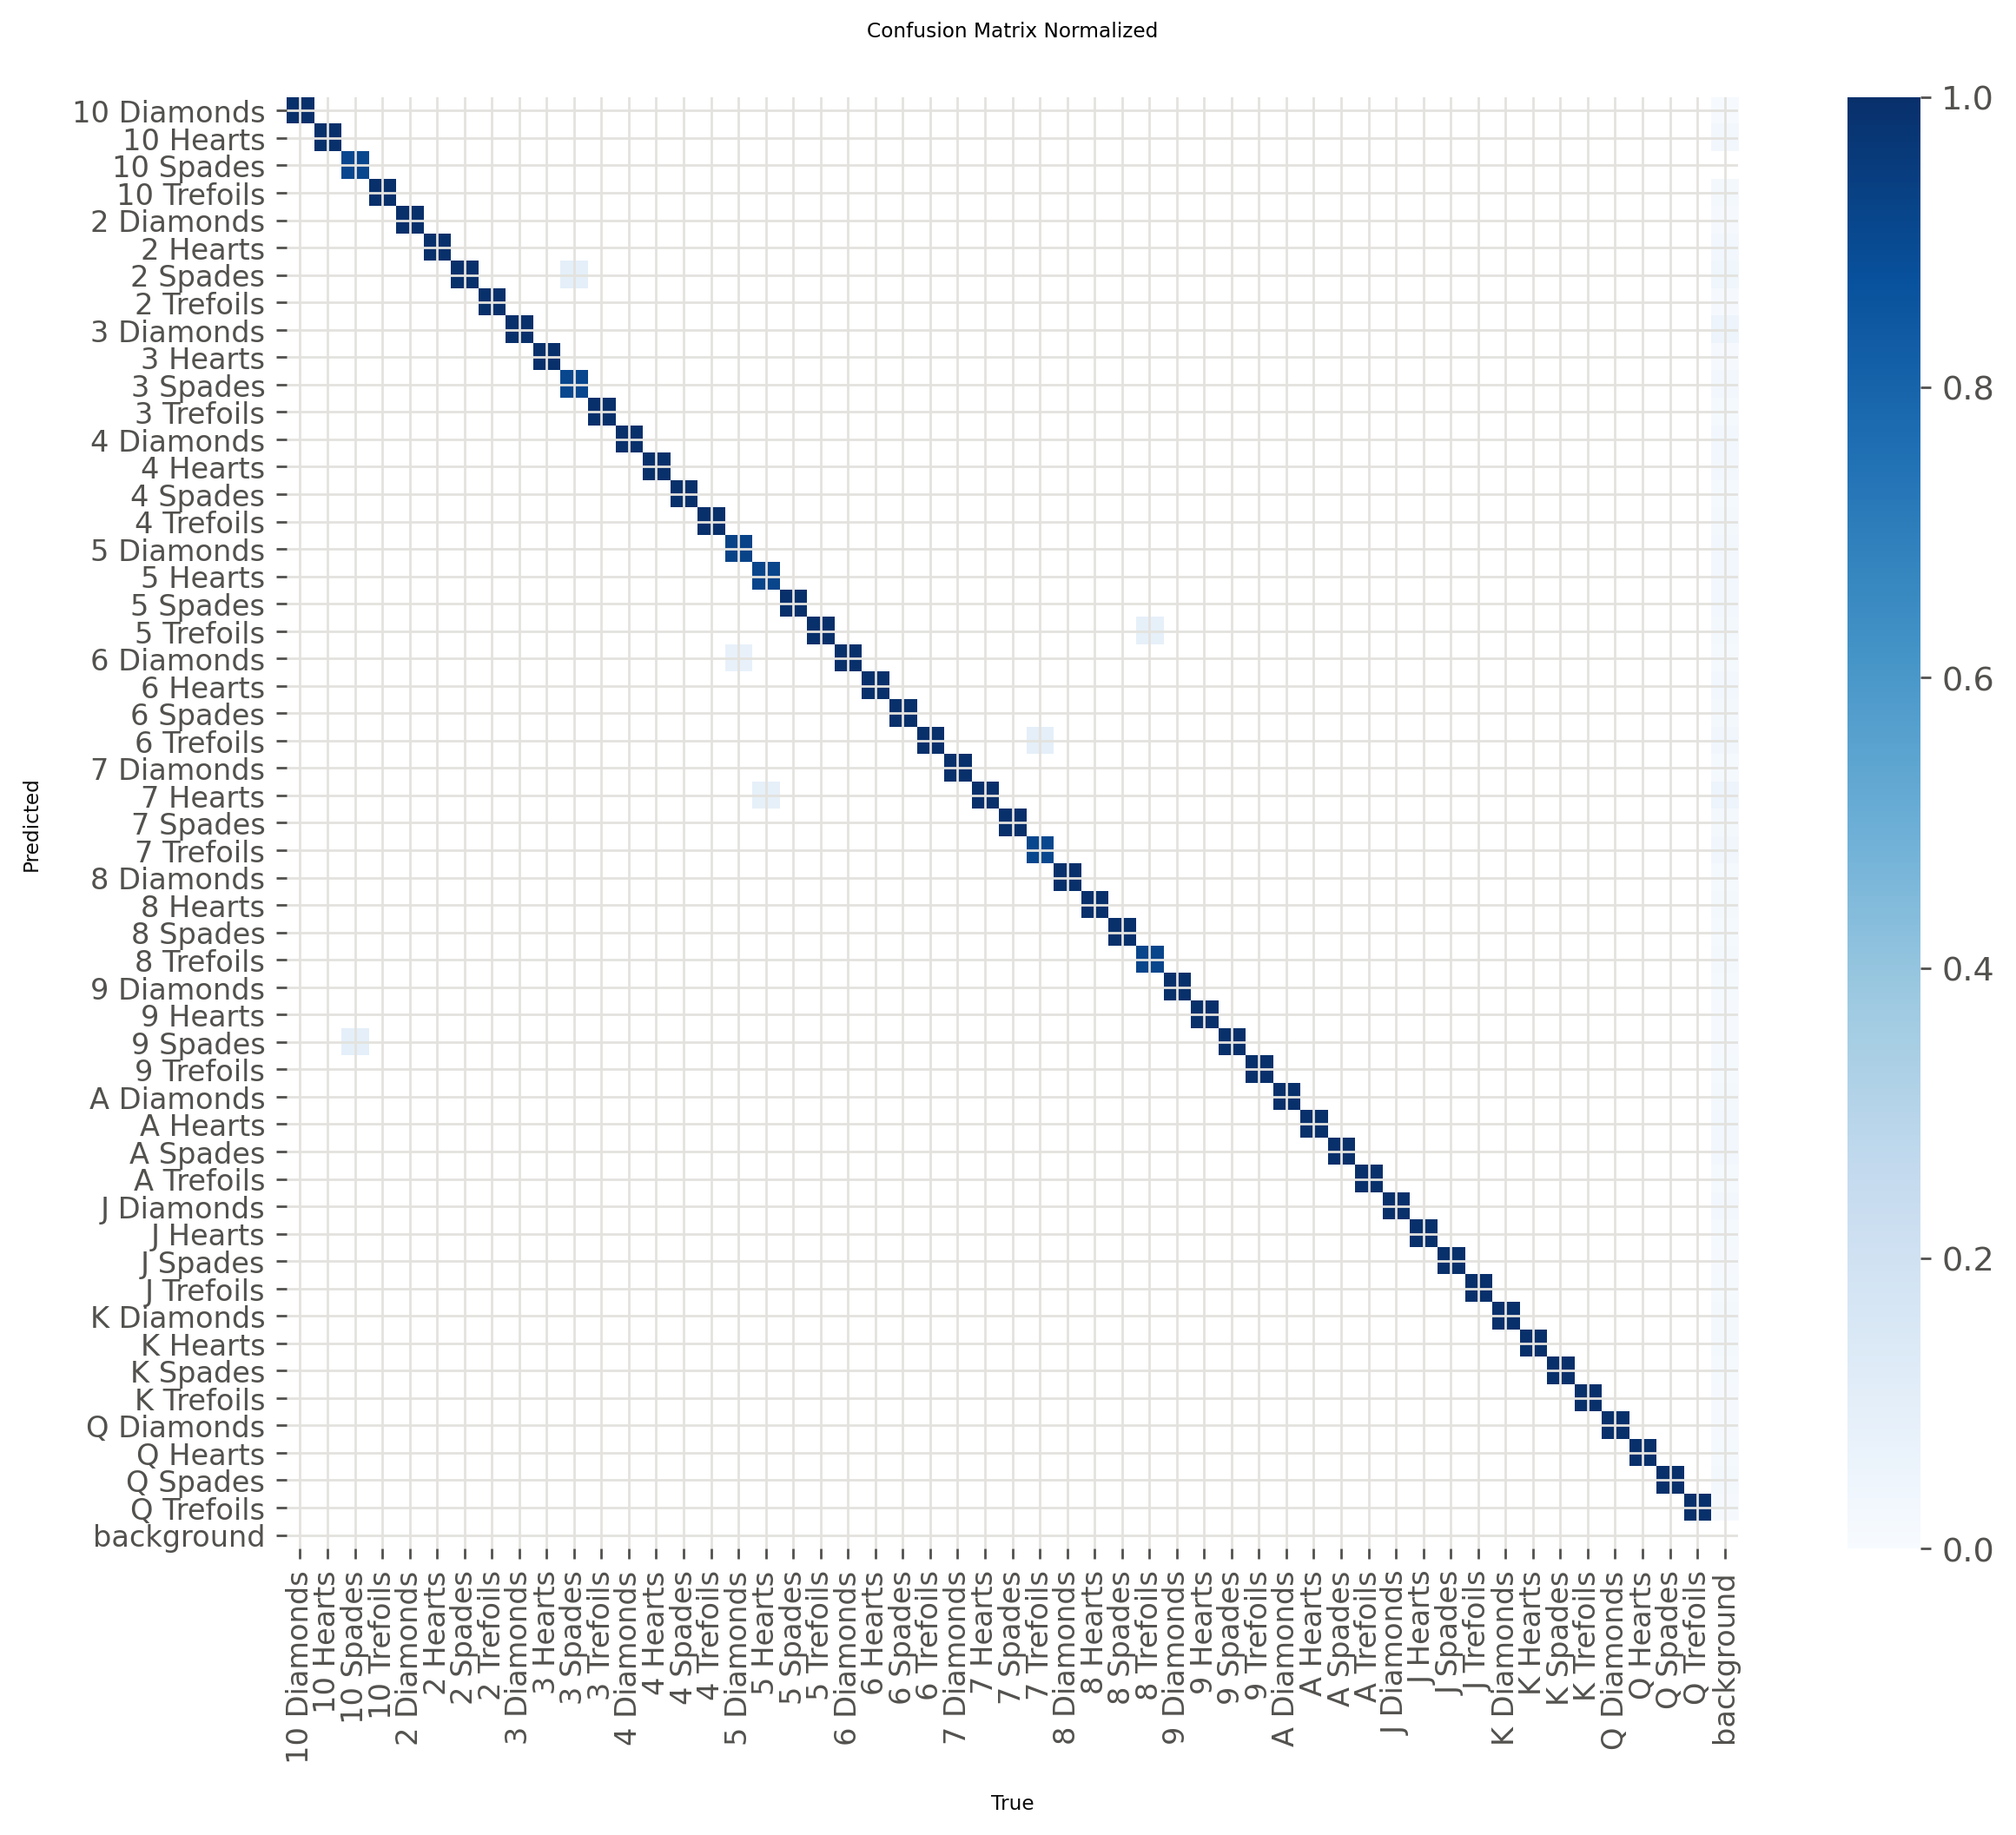

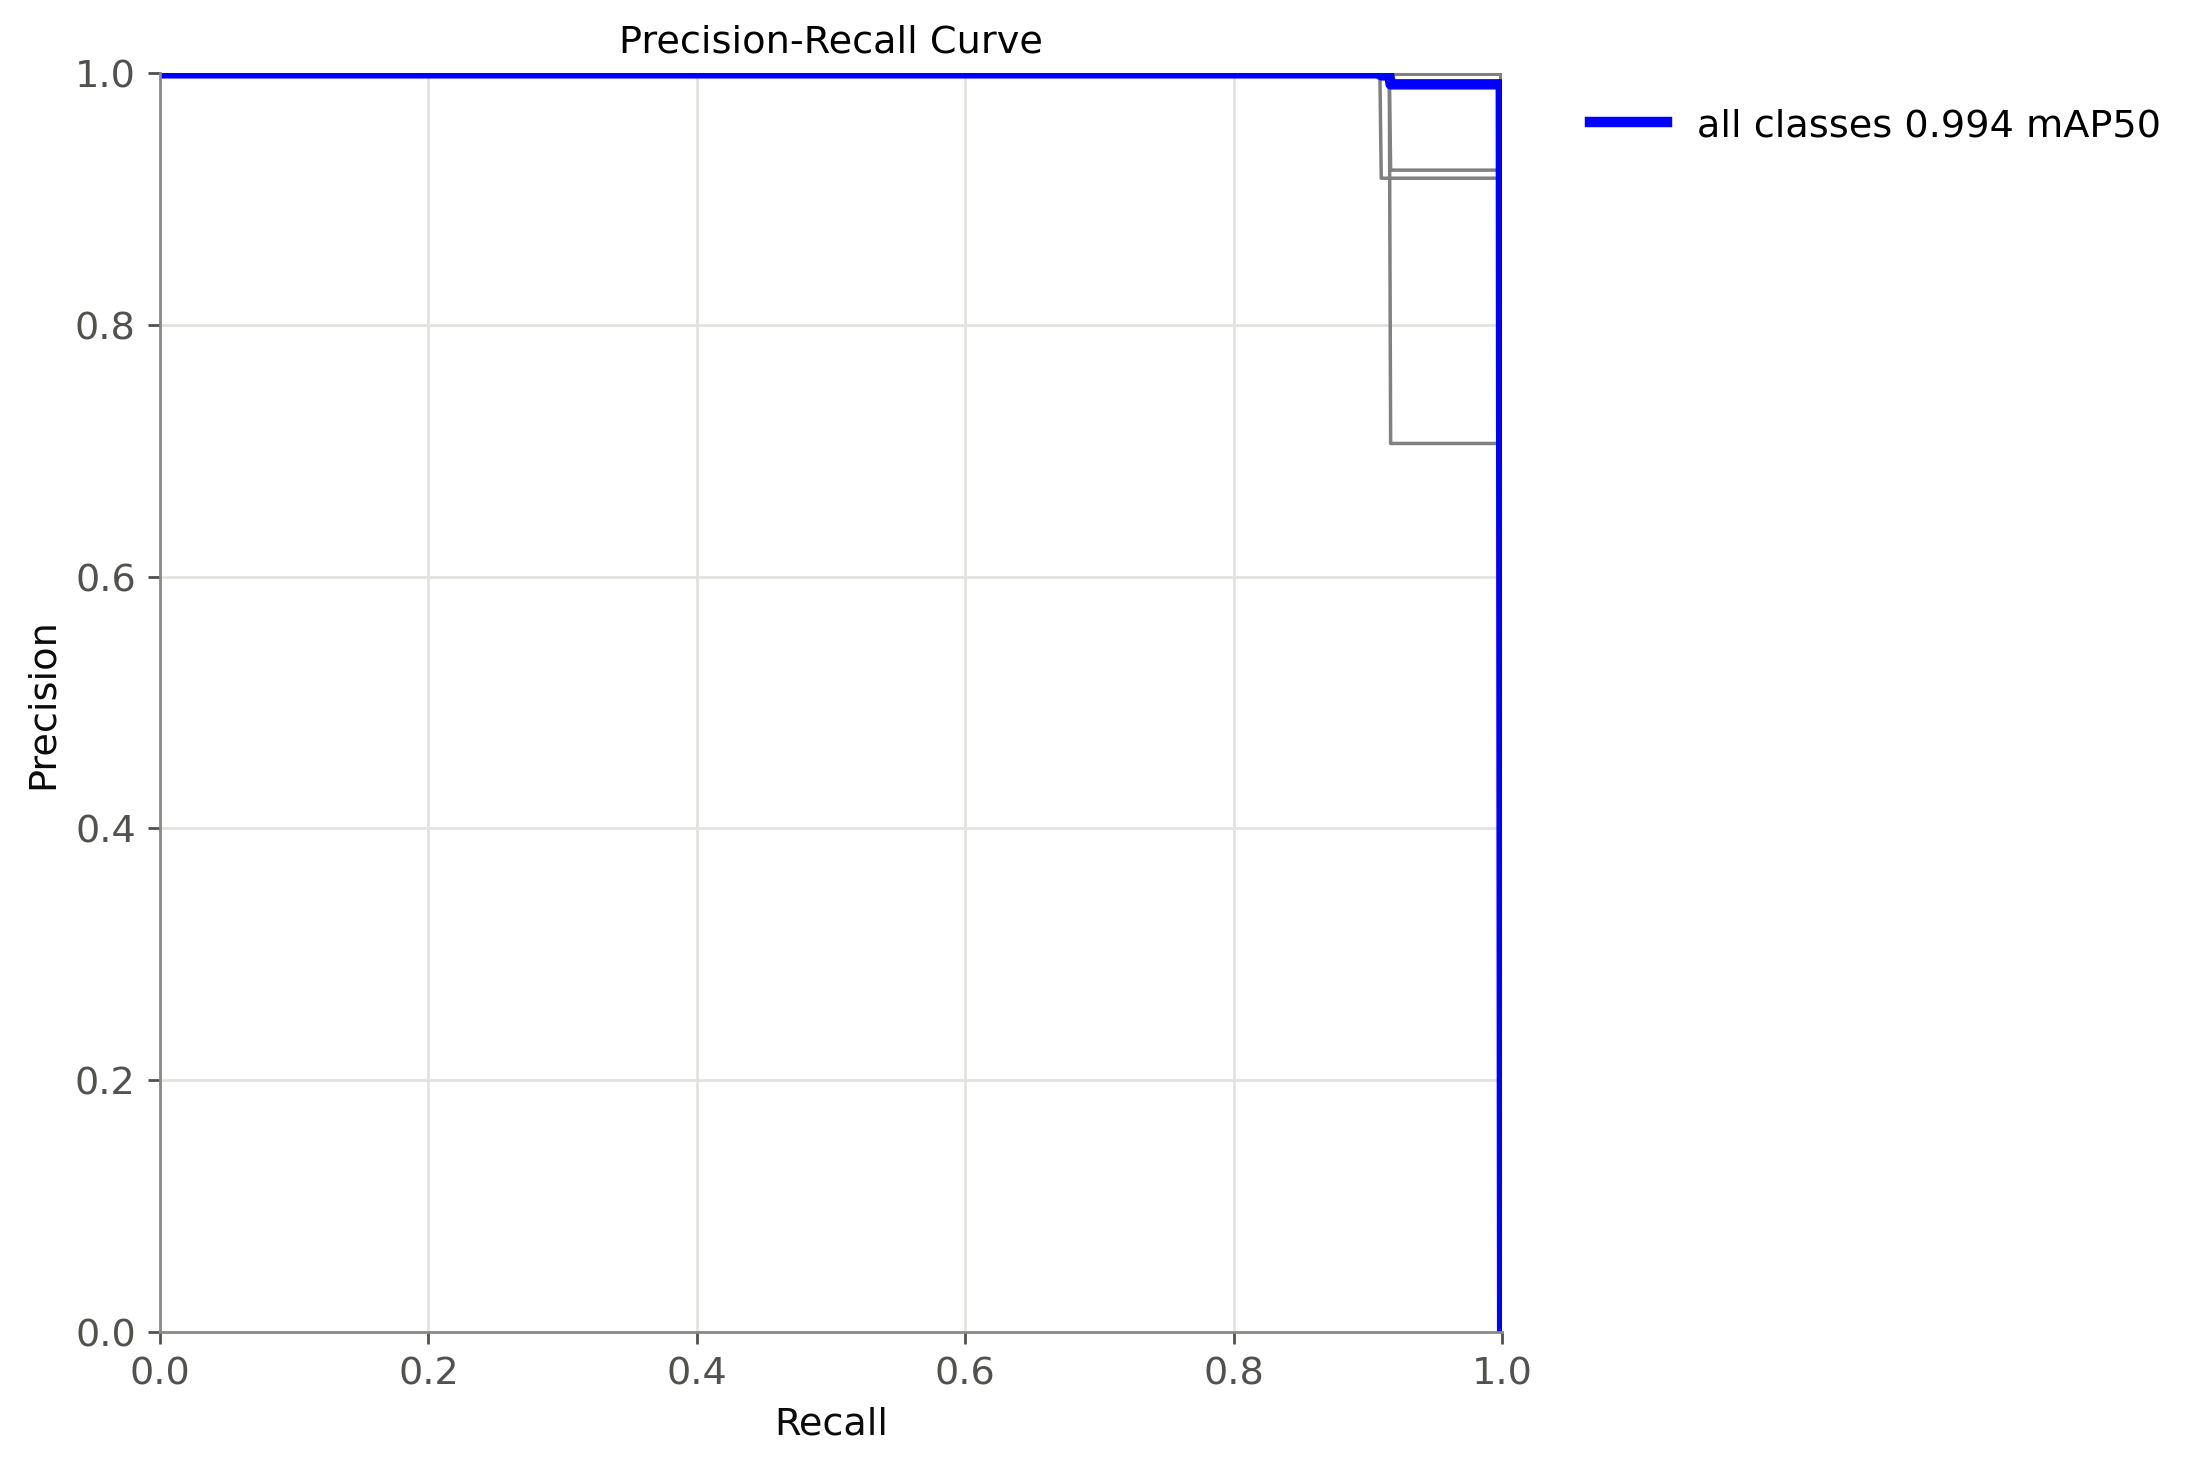

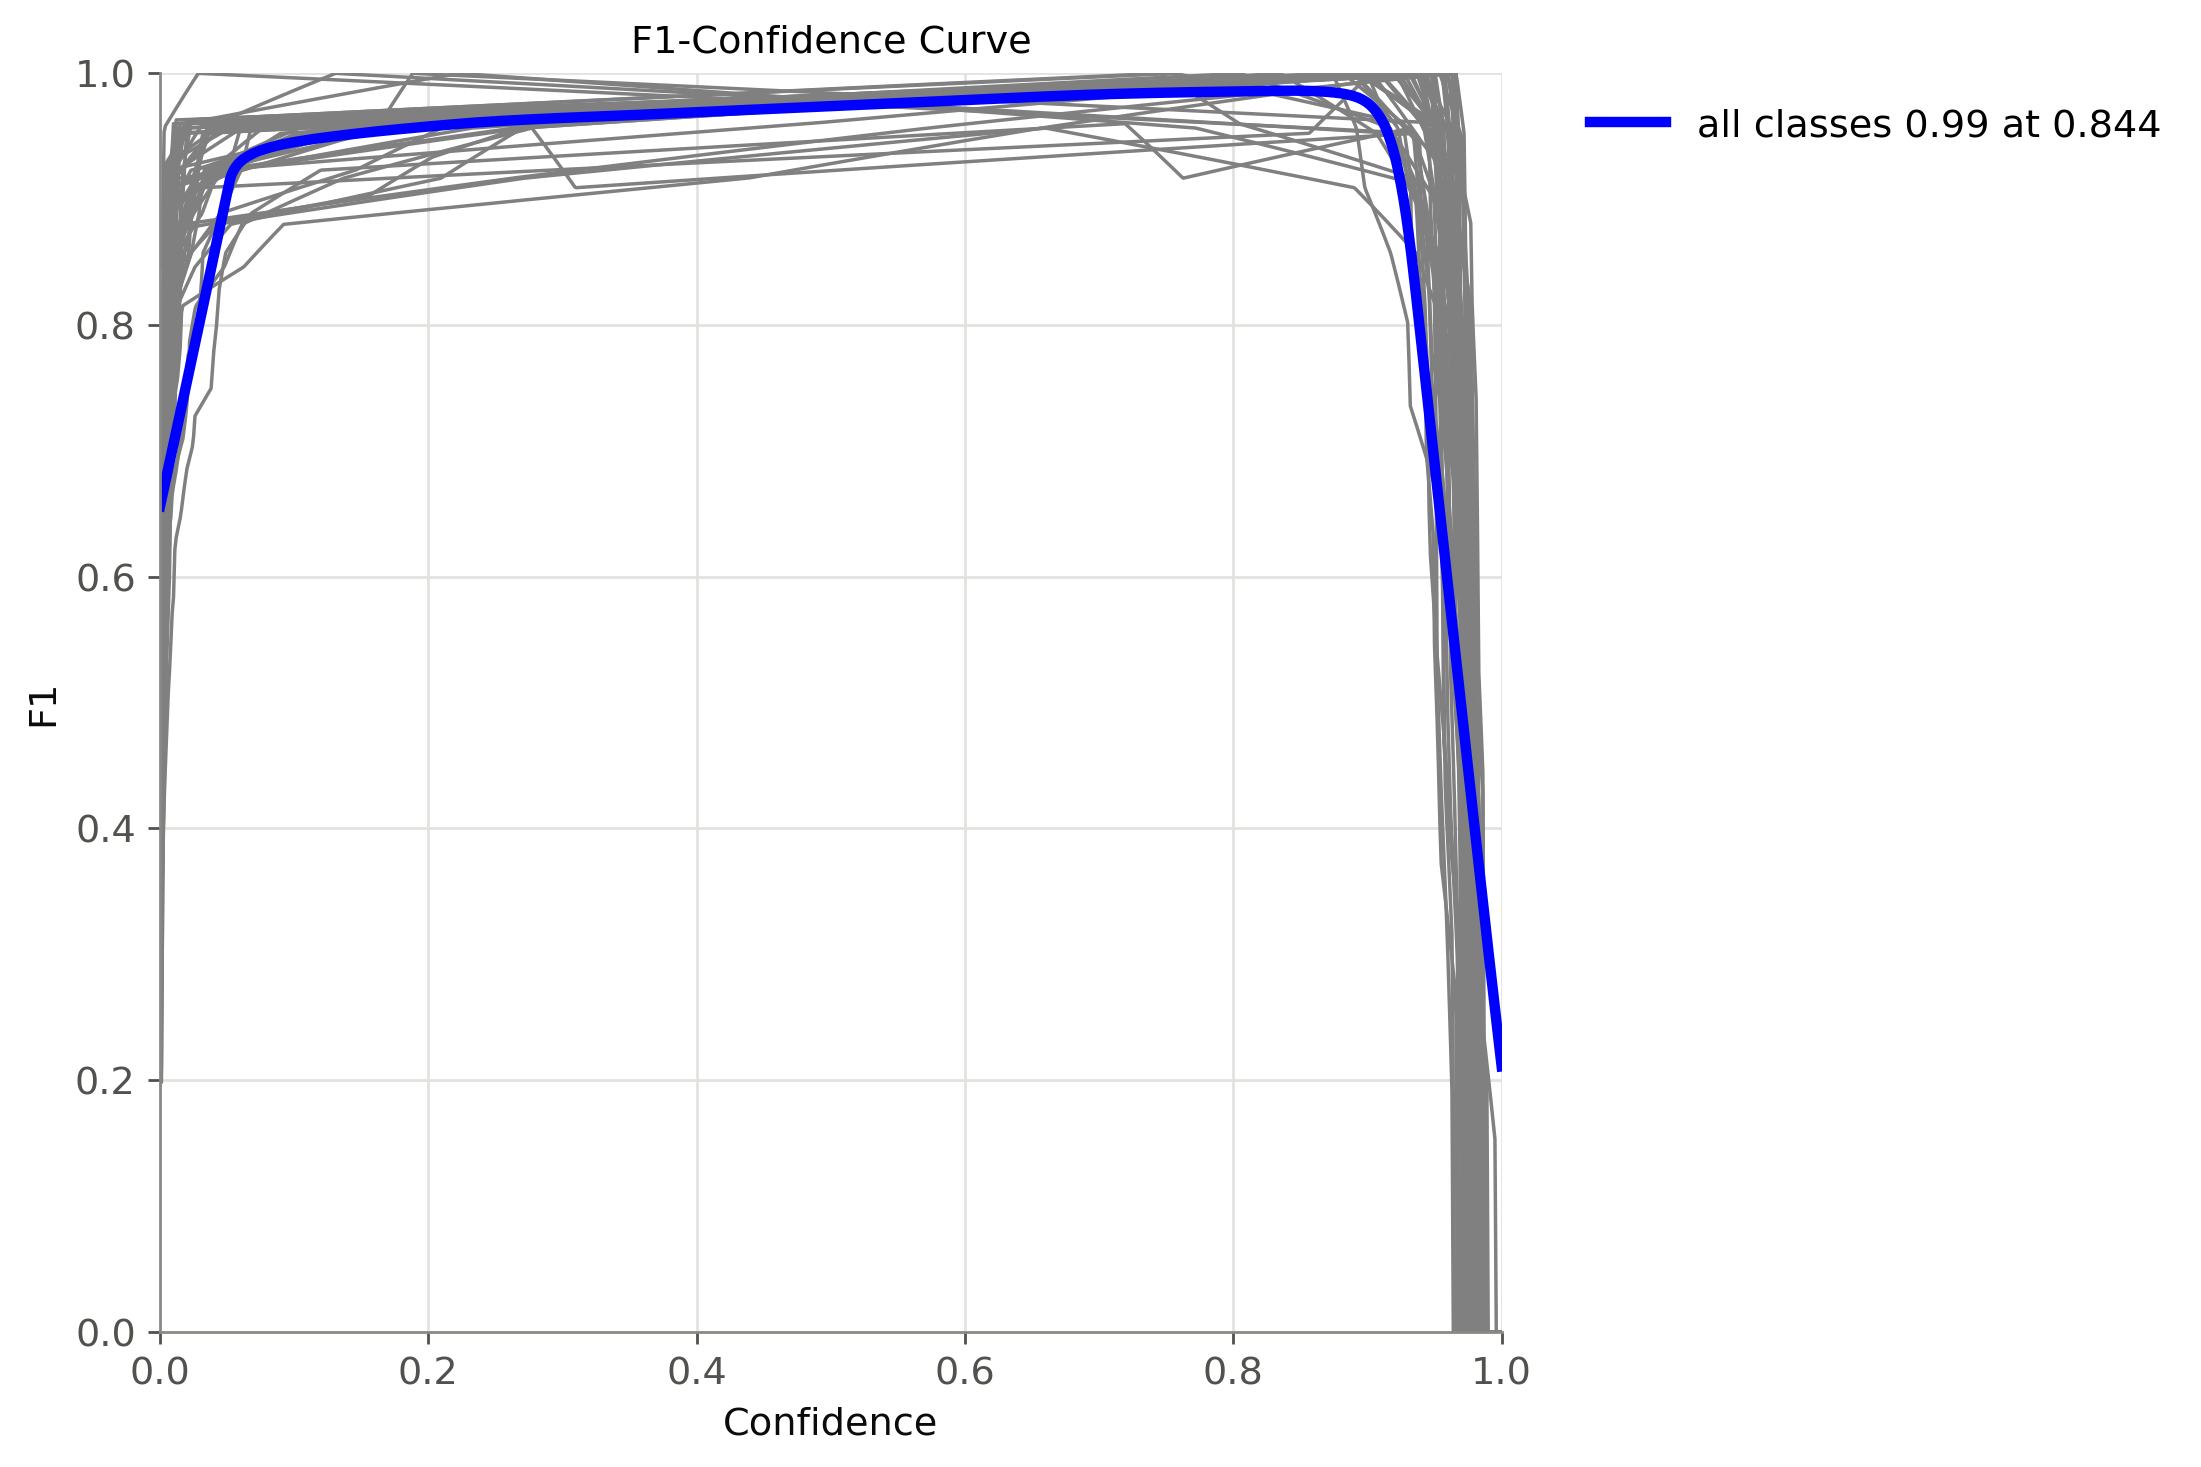

In [16]:
for s in SPLITS:
    pasta = Path(metricas[s]["pasta"])
    print(f"\n----- {NOME[s]} ({pasta}) -----")
    for nome in ["confusion_matrix_normalized.png", "BoxPR_curve.png", "BoxF1_curve.png"]:
        arq = pasta / nome
        if arq.exists():
            shutil.copy(arq, FIGURAS / f"{s}_{nome}")
            display(IPImage(filename=str(arq), width=520))

In [17]:
teste_cls = por_classe_metr["test"].sort_values("mAP50-95")
for s in SPLITS:
    por_classe_metr[s].to_csv(TABELAS / f"metricas_por_classe_{s}.csv", index=False, sep=";", decimal=",")
print("10 classes com menor mAP50-95 no teste:")
display(teste_cls.head(10).style.format({c: "{:.3f}" for c in ["P", "R", "mAP50", "mAP50-95"]}).hide(axis="index"))

10 classes com menor mAP50-95 no teste:


Classe,P,R,mAP50,mAP50-95
10 Diamonds,0.997,1.000,0.995,0.916
8 Trefoils,1.000,0.850,0.971,0.918
8 Spades,0.993,1.000,0.995,0.963
5 Hearts,1.000,0.882,0.995,0.963
5 Diamonds,1.000,0.935,0.995,0.964
8 Diamonds,0.995,1.000,0.995,0.965
7 Trefoils,0.987,0.909,0.988,0.966
5 Trefoils,1.000,0.971,0.995,0.968
9 Diamonds,0.988,1.000,0.995,0.972
J Hearts,0.990,1.000,0.995,0.972


In [18]:
linhas = []
for arq in sorted(RAIZ.glob("*/metricas.json")):
    d = json.load(open(arq))
    for s in SPLITS:
        if s in d["metricas"]:
            linhas.append({"Modelo": Path(d["modelo"]).stem, "Épocas": d["epocas"], "Conjunto": NOME[s],
                           **{k: d["metricas"][s][k] for k in ["P", "R", "F1", "mAP50", "mAP50-95"]}})
comp = pd.DataFrame(linhas)
if len(comp):
    comp.to_csv(RAIZ / "comparacao_modelos.csv", index=False, sep=";", decimal=",")
    display(comp[comp.Conjunto == "Teste"].style.format({c: "{:.3f}" for c in ["P", "R", "F1", "mAP50", "mAP50-95"]}).hide(axis="index"))
    if comp.groupby("Modelo")["Épocas"].first().nunique() > 1:
        print("ATENÇÃO: os modelos foram treinados com números diferentes de épocas; a comparação não é justa.")

Modelo,Épocas,Conjunto,P,R,F1,mAP50,mAP50-95
yolov8n,50,Teste,0.990,0.984,0.987,0.994,0.984


In [19]:
zip_path = shutil.make_archive(f"/content/resultados_{NOME_RUN}", "zip", SAIDA)
print("Arquivo:", zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    pass

Arquivo: /content/resultados_yolov8n_50ep.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>